# Does Bike Demand Stay Low After Bad Weather Ends?

**DT8013 Data Mining: project notebook (Supplementary B)**
Group: Binay Kumar Sah & Kabir Tamari · Dataset: UCI Bike Sharing (Capital Bikeshare, Washington D.C., 2011–2012) [Fanaee-T & Gama, 2013]

**Research question.** When rain or snow stops, how many hours does it take for bike demand to return to normal, and do **commuters (registered)** and **casual riders** recover at different speeds?

**Why the company should care.** If demand lags behind the weather, a forecast that only looks at the *current* weather over-predicts the hours right after rain. The company then rebalances bikes too early, and misses the window where a casual-rider promotion could pull demand back.

**How the notebook answers it**

| § | Step (project task) | Main method | Evaluation |
|---|---|---|---|
| 1 | Cleaning (task 1) | data audit, rule-based fixes | cleaning log |
| 2 | Descriptive statistics (task 2) | summaries, profiles | n/a |
| 3 | Anomalies (task 1) | robust z, HBOS, kNN, LOF + external evidence | detector agreement, explained share |
| 4 | Feature engineering (task 5) | weather episodes, hours since bad weather, expected demand | n/a |
| 5 | Dimension reduction (task 3) | PCA of daily demand shapes and recovery curves | explained variance |
| 6 | RQ-A (task 4) | episode recovery curves, recovery time | paired Wilcoxon, bootstrap CI |
| 7 | RQ-B (task 4) | regression on lagged weather (OLS + gradient boosting) | MAE/RMSE on post-rain hours, chronological split |
| 8 | RQ-C (task 4) | association rules (Apriori) | support / confidence / **lift**, 2011→2012 stability |
| 9 | Business translation | lost rides, timing windows | n/a |

Every section starts with a **Why / Source** cell. `[Lecture X – Slide Y]` marks a citation that still has to be checked against the course slides.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
DATA = Path('bike+sharing+dataset')
FIG = Path('figures')
FIG.mkdir(exist_ok=True)

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.precision', 3)

# one colour per rider type, used in every figure (registered = blue, casual = orange)
C_REG, C_CAS, C_3, C_GREY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
COL = {'registered': C_REG, 'casual': C_CAS}
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
    'lines.linewidth': 2, 'axes.titleweight': 'bold', 'axes.titlesize': 11,
})

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 1 · Data audit and cleaning

**Why.** The criteria grade *how clear and compelling* the cleaning is. So we do not just call `dropna()`: every problem is found with evidence, then fixed with a stated reason. The research question is about *hours after* bad weather, so the hourly table must be a **complete, regular time grid**. Otherwise "3 hours after the rain" points to the wrong row.

**Source.** Data quality and preprocessing [Lecture: Data preprocessing – Slide ?]. Noise vs meaningful anomaly [Lecture: Anomaly Detection (1) – Slide 18]. Dataset README (Fanaee-T & Gama, 2013).

In [2]:
day = pd.read_csv(DATA / 'day.csv', parse_dates=['dteday'])
hour = pd.read_csv(DATA / 'hour.csv', parse_dates=['dteday'])
hour['ts'] = hour['dteday'] + pd.to_timedelta(hour['hr'], unit='h')

audit = pd.Series({
    'rows day.csv': len(day),
    'rows hour.csv': len(hour),
    'hours in a full 731 x 24 grid': 731 * 24,
    'missing hours': 731 * 24 - len(hour),
    'NaN cells in hour.csv': int(hour.isna().sum().sum()),
    'duplicate rows in hour.csv': int(hour.duplicated().sum()),
    'cnt == casual + registered (every row)': bool((hour.cnt == hour.casual + hour.registered).all()),
    'daily cnt == sum of hourly cnt (every day)': bool((hour.groupby('dteday').cnt.sum().values == day.cnt.values).all()),
    'smallest hourly cnt': int(hour.cnt.min()),
    'hours with hum == 0': int((hour.hum == 0).sum()),
    'hours with windspeed == 0': int((hour.windspeed == 0).sum()),
    'hours with weathersit == 4': int((hour.weathersit == 4).sum()),
}, name='value')
audit.to_frame()

,value
rows day.csv,731
rows hour.csv,17379
hours in a full 731 x 24 grid,17544
missing hours,165
NaN cells in hour.csv,0
duplicate rows in hour.csv,0
cnt == casual + registered (every row),True
daily cnt == sum of hourly cnt (every day),True
smallest hourly cnt,1
hours with hum == 0,22


### 1.1 Missing hours: two different causes

There are no NaN cells, but **165 hours are simply absent**. The smallest hourly count in the file is 1, so an hour with *zero* rentals was never written. We split the gaps by length and time of day to see whether they are "nobody rode" or "no data".

In [3]:
full_index = pd.date_range(hour.ts.min(), hour.ts.max(), freq='h')
missing = full_index.difference(hour.ts)
run_id = (pd.Series(missing).diff() != pd.Timedelta('1h')).cumsum().values
gaps = (pd.DataFrame({'ts': missing, 'run': run_id})
        .groupby('run').ts.agg(start='min', end='max', hours='size'))

print('gap length (h) -> number of gaps :', gaps.hours.value_counts().sort_index().to_dict())
print('missing hours by hour of day      :', pd.Series(missing.hour).value_counts().sort_index().to_dict())
gaps.sort_values('hours', ascending=False).head(6)

gap length (h) -> number of gaps : {1: 64, 2: 6, 6: 1, 12: 1, 13: 1, 22: 1, 36: 1}
missing hours by hour of day      : {0: 5, 1: 7, 2: 16, 3: 34, 4: 34, 5: 14, 6: 6, 7: 4, 8: 4, 9: 4, 10: 4, 11: 4, 12: 3, 13: 2, 14: 2, 15: 2, 16: 1, 17: 1, 18: 3, 19: 3, 20: 3, 21: 3, 22: 3, 23: 3}


,start,end,hours
run,,,
71,2012-10-29 01:00:00,2012-10-30 12:00:00,36
17,2011-01-26 18:00:00,2011-01-27 15:00:00,22
52,2011-08-27 18:00:00,2011-08-28 06:00:00,13
10,2011-01-18 00:00:00,2011-01-18 11:00:00,12
31,2011-02-22 00:00:00,2011-02-22 05:00:00,6
16,2011-01-26 03:00:00,2011-01-26 04:00:00,2


**Reading.** There are two kinds of gaps.

- **70 short gaps (1–2 h), almost all between 02:00 and 05:00.** These are night hours in which nobody rented a bike, so they are filled with **0 rides**.
- **5 long gaps (≥ 6 h).** They fall exactly on **Hurricane Sandy** (29–30 Oct 2012, 36 h), the **26–27 Jan 2011 snowstorm** (22 h), **Hurricane Irene** (27–28 Aug 2011, 13 h), 18 Jan 2011 (12 h) and 22 Feb 2011 (6 h). News archives confirm that **Capital Bikeshare itself was closed**:
  - Irene: closed at 18:00 on 27 Aug 2011 (DCist). The gap starts at exactly 18:00.
  - Sandy: closed from 01:00 on 29 Oct 2012 for about 36 h (ARLnow, WTOP). The gap starts at 01:00 and lasts 36 h.
  - The 26 Jan 2011 snowstorm: the system was shut down that night.

  So demand was *not observed*, and imputing it would invent rides. These hours stay `NaN` with an `outage` flag and are left out of every model. (18 Jan and 22 Feb 2011 could not be confirmed externally; they are treated the same way because they look the same.)

The ≥ 6 h threshold is not delicate: no gap has a length between 3 and 5 hours, so any threshold in that range gives the same split.

In [4]:
OUTAGE_MIN_HOURS = 6
outage_hours = pd.DatetimeIndex(np.concatenate(
    [pd.date_range(g.start, g.end, freq='h') for g in gaps.itertuples() if g.hours >= OUTAGE_MIN_HOURS]))

df = hour.set_index('ts').reindex(full_index)
df.index.name = 'ts'
df['outage'] = df.index.isin(outage_hours)
df['zero_fill'] = df['cnt'].isna() & ~df['outage']

# calendar columns exist for every hour, including the inserted ones
df['dteday'] = df.index.normalize()
df['hr'] = df.index.hour
cal = day.set_index('dteday')[['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday']]
df[cal.columns] = cal.reindex(df['dteday']).values.astype(int)

# hours with zero rentals -> 0 ; outage hours stay NaN
df.loc[df.zero_fill, ['casual', 'registered', 'cnt']] = 0

# weather has no row for inserted hours: carry the last observation forward (weather persists hour to hour)
WCOLS = ['weathersit', 'temp', 'atemp', 'hum', 'windspeed']
df['weather_filled'] = df['weathersit'].isna()
df[WCOLS] = df[WCOLS].ffill()
print(f'zero-rental hours filled with 0: {df.zero_fill.sum()} | outage hours kept as NaN: {df.outage.sum()} | grid: {len(df)} hours')

zero-rental hours filled with 0: 76 | outage hours kept as NaN: 89 | grid: 17544 hours


### 1.2 Sensor errors, units and labels

**Temperature units: the two official descriptions disagree.** The `Readme.txt` shipped with the data says `temp` was *divided by 41*. The UCI dataset page says hourly `temp` = (t − t_min)/(t_max − t_min) with **t_min = −8, t_max = +39** (atemp: −16, +50). We check which one is physically plausible.

In [5]:
readme_c = df.temp * 41                      # Readme.txt version
uci_c = -8 + 47 * df.temp                    # UCI page version
storm = df.loc['2011-01-26 12:00':'2011-01-26 17:00', 'temp']
print(f'coldest hour 2011-12  -> Readme: {readme_c.min():5.1f} °C | UCI: {uci_c.min():5.1f} °C')
print(f'hottest hour 2011-12  -> Readme: {readme_c.max():5.1f} °C | UCI: {uci_c.max():5.1f} °C')
print(f'26 Jan 2011 snowstorm (12–17 h) -> Readme: {(storm * 41).mean():4.1f} °C | UCI: {(-8 + 47 * storm).mean():4.1f} °C')

coldest hour 2011-12  -> Readme:   0.8 °C | UCI:  -7.1 °C
hottest hour 2011-12  -> Readme:  41.0 °C | UCI:  39.0 °C
26 Jan 2011 snowstorm (12–17 h) -> Readme:  8.9 °C | UCI:  2.2 °C


With the Readme formula, Washington D.C. would never have gone below +0.8 °C in two winters, and the 26 Jan 2011 snowstorm (about 5 inches of snow, NOAA WPC) would have happened at about 9 °C. Both are impossible. The UCI formula gives −7 °C for the coldest hour and about 2 °C during the storm, which is plausible. **We use the UCI formula.** This matters for the project: the rain-vs-snow proxy below is a temperature threshold.

In [6]:
# real units (UCI dataset page): temp & atemp are min-max scaled, hum / wind divided by their max
df['temp_c'] = -8 + 47 * df.temp
df['atemp_c'] = -16 + 66 * df.atemp
df['hum_pct'] = df.hum * 100
df['wind_kmh'] = df.windspeed * 67

# (a) humidity 0 % for a whole rainy day -> sensor dropout
bad_hum = df.hum_pct.eq(0)
print('hum == 0 on:', df.loc[bad_hum, 'dteday'].dt.date.unique(), '| weathersit that day:', df.loc[bad_hum, 'weathersit'].value_counts().to_dict())
hum_med = df[~bad_hum].groupby(['mnth', 'weathersit']).hum_pct.median()
df.loc[bad_hum, 'hum_pct'] = hum_med.reindex(pd.MultiIndex.from_frame(df.loc[bad_hum, ['mnth', 'weathersit']])).values

# (b) feels-like temperature stuck at a single value for a whole day
resid = df.atemp_c - np.polyval(np.polyfit(df.temp_c, df.atemp_c, 1), df.temp_c)
bad_atemp = resid.lt(-8)          # feels-like far BELOW air temperature; positive residuals (heat index) are real
print('atemp residual < -8 °C on:', df.loc[bad_atemp, 'dteday'].dt.date.unique(),
      '| distinct atemp values that day:', df.loc[bad_atemp, 'atemp'].nunique(),
      f'| corr(temp, atemp) elsewhere: {np.corrcoef(df.temp_c[~bad_atemp], df.atemp_c[~bad_atemp])[0, 1]:.3f}')
coef = np.polyfit(df.loc[~bad_atemp, 'temp_c'], df.loc[~bad_atemp, 'atemp_c'], 2)
df.loc[bad_atemp, 'atemp_c'] = np.polyval(coef, df.loc[bad_atemp, 'temp_c'])

# (c) wind: is 0 a missing value?
print('smallest wind speeds (km/h):', np.sort(df.wind_kmh.round(1).unique())[:6])

# (d) season labels: on which dates does the season code change?
changes = day.loc[day.season.diff().fillna(1).ne(0), ['dteday', 'season']].head(5)
print('season code changes on:', [(str(d.date()), s) for d, s in changes.values])
SEASON = {1: 'winter', 2: 'spring', 3: 'summer', 4: 'fall'}
df['season_name'] = df.season.map(SEASON)

# (e) weathersit 4 has only 3 hours in two years -> merge into 3 = "bad weather"
df['weathersit'] = df.weathersit.clip(upper=3).astype(int)

hum == 0 on: [datetime.date(2011, 3, 10)] | weathersit that day: {3.0: 22, 2.0: 2}
atemp residual < -8 °C on: [datetime.date(2012, 8, 17)] | distinct atemp values that day: 1 | corr(temp, atemp) elsewhere: 0.992
smallest wind speeds (km/h): [ 0.  6.  7.  9. 11. 13.]
season code changes on: [('2011-01-01', 1), ('2011-03-21', 2), ('2011-06-21', 3), ('2011-09-23', 4), ('2011-12-21', 1)]


In [7]:
cleaning_log = pd.DataFrame([
    ['hours absent, 1–2 h gaps at night', int(df.zero_fill.sum()),
     'smallest hourly cnt is 1: zero-rental hours were never written',
     'insert the hour with 0 rides', 'keeps a regular hourly grid, so "hours since rain" is correct'],
    ['long gaps (≥ 6 h) on storm days', int(df.outage.sum()),
     'the gaps match Sandy, Irene and the Jan-2011 snowstorm',
     'counts NaN + outage flag, left out of models', 'demand was not observed; imputing would invent rides'],
    ['no weather row for inserted hours', int(df.weather_filled.sum()),
     'reindexing creates hours without weather',
     'forward-fill from the previous hour', 'weather is persistent; storm episodes are not cut in two'],
    ['humidity 0 % all day on 2011-03-10', int(bad_hum.sum()),
     '0 % humidity on a rainy day is physically impossible',
     'median humidity of the same month and weather type', 'conditional median keeps the rain–humidity link'],
    ['temperature scale wrong in Readme.txt', len(df),
     'Readme ÷41 gives min +0.8 °C over two D.C. winters and 9 °C during a snowstorm',
     'use the UCI formula t = −8 + 47·temp (atemp: −16 + 66·atemp)', 'the snow proxy and temperature bands depend on correct °C'],
    ['atemp stuck at one value on 2012-08-17', int(bad_atemp.sum()),
     'feels-like ≈ 0 °C at ≈ 24 °C air temperature (residual > 8 °C)',
     'predict from temp (quadratic fit on the other hours)', 'atemp is almost a function of temp (r ≈ 0.99)'],
    ['season labels wrong in README', 4,
     'codes change on 21 Mar, 21 Jun, 23 Sep, 21 Dec: code 1 = winter',
     'rename 1–4 to winter/spring/summer/fall', 'README calls 1 "springer"; seasonal plots would mislead'],
    ['weathersit = 4', int((hour.weathersit == 4).sum()),
     'only 3 hours in two years', 'merge into 3 ("bad weather")', 'a class with 3 rows cannot be estimated'],
    ['windspeed = 0', int((df.wind_kmh == 0).sum()),
     'next value is 6 km/h; nothing between 0 and 6',
     'keep as real "calm"', 'METAR reports wind < 3 kt (5.6 km/h) as calm'],
], columns=['issue', 'rows', 'evidence', 'decision', 'why'])
cleaning_log

,issue,rows,evidence,decision,why
0,"hours absent, 1–2 h gaps at night",76,smallest hourly cnt is 1: zero-rental hours were never written,insert the hour with 0 rides,"keeps a regular hourly grid, so ""hours since rain"" is correct"
1,long gaps (≥ 6 h) on storm days,89,"the gaps match Sandy, Irene and the Jan-2011 snowstorm","counts NaN + outage flag, left out of models",demand was not observed; imputing would invent rides
2,no weather row for inserted hours,165,reindexing creates hours without weather,forward-fill from the previous hour,weather is persistent; storm episodes are not cut in two
3,humidity 0 % all day on 2011-03-10,24,0 % humidity on a rainy day is physically impossible,median humidity of the same month and weather type,conditional median keeps the rain–humidity link
4,temperature scale wrong in Readme.txt,17544,Readme ÷41 gives min +0.8 °C over two D.C. winters and 9 °C during a snowstorm,use the UCI formula t = −8 + 47·temp (atemp: −16 + 66·atemp),the snow proxy and temperature bands depend on correct °C
5,atemp stuck at one value on 2012-08-17,24,feels-like ≈ 0 °C at ≈ 24 °C air temperature (residual > 8 °C),predict from temp (quadratic fit on the other hours),atemp is almost a function of temp (r ≈ 0.99)
6,season labels wrong in README,4,"codes change on 21 Mar, 21 Jun, 23 Sep, 21 Dec: code 1 = winter",rename 1–4 to winter/spring/summer/fall,"README calls 1 ""springer""; seasonal plots would mislead"
7,weathersit = 4,3,only 3 hours in two years,"merge into 3 (""bad weather"")",a class with 3 rows cannot be estimated
8,windspeed = 0,2189,next value is 6 km/h; nothing between 0 and 6,"keep as real ""calm""",METAR reports wind < 3 kt (5.6 km/h) as calm


## 2 · Descriptive statistics

**Why.** Before asking *how fast* demand recovers we need to know (i) how large and how skewed demand is, (ii) whether casual and registered riders really behave differently (if not, the second half of the RQ is pointless), and (iii) how big the weather effect is in the first place.

**Source.** Descriptive statistics and data exploration [Lecture: Data exploration – Slide ?]; boxplots and histograms [Lecture: Anomaly Detection (1) – Slides 22, 24].

In [8]:
daily = df.groupby('dteday').agg(
    casual=('casual', 'sum'), registered=('registered', 'sum'), cnt=('cnt', 'sum'),
    temp_c=('temp_c', 'mean'), atemp_c=('atemp_c', 'mean'), hum_pct=('hum_pct', 'mean'), wind_kmh=('wind_kmh', 'mean'),
    bad_hours=('weathersit', lambda s: int((s == 3).sum())), outage_hours=('outage', 'sum'),
    workingday=('workingday', 'first'), holiday=('holiday', 'first'), weekday=('weekday', 'first'),
    season_name=('season_name', 'first'), yr=('yr', 'first'), mnth=('mnth', 'first'))
daily['weathersit'] = day.set_index('dteday').weathersit.clip(upper=3)
daily['casual_share'] = daily.casual / daily.cnt

desc = daily[['cnt', 'registered', 'casual', 'casual_share', 'temp_c', 'hum_pct', 'wind_kmh']].describe().T
desc['skew'] = daily[desc.index].skew()
desc

,count,mean,std,min,25%,50%,75%,max,skew
cnt,731.0,4504.349,1937.211,22.000,3152.000,4548.000,5956.000,8714.000,-0.047
registered,731.0,3656.172,1560.256,20.000,2497.000,3662.000,4776.500,6946.000,0.044
casual,731.0,848.176,686.622,2.000,315.500,713.000,1096.000,3410.000,1.266
casual_share,731.0,0.176,0.107,0.013,0.099,0.149,0.215,0.510,0.939
temp_c,731.0,15.275,8.610,-5.298,7.902,15.422,22.805,32.498,-0.058
hum_pct,731.0,62.998,14.096,18.792,52.250,62.917,73.188,97.250,0.031
wind_kmh,731.0,12.814,5.265,1.500,9.042,12.125,15.750,34.000,0.731


In [9]:
h = df[~df.outage]
by_weather = h.groupby('weathersit')[['registered', 'casual']].mean()
by_weather_pct = (by_weather / by_weather.loc[1] - 1) * 100
by_day = daily.groupby('workingday')[['registered', 'casual', 'casual_share']].mean().rename(index={0: 'weekend/holiday', 1: 'working day'})
print('Mean rides per hour by weather situation (1 = clear, 2 = mist, 3 = rain/snow) and % change vs clear:')
display(pd.concat([by_weather.round(1), by_weather_pct.round(1).add_suffix(' %')], axis=1))
print('Mean rides per day by day type:')
display(by_day.round(2))

Mean rides per hour by weather situation (1 = clear, 2 = mist, 3 = rain/snow) and % change vs clear:


,registered,casual,registered %,casual %
weathersit,,,,
1,163.7,40.4,0.0,0.0
2,145.0,29.5,-11.5,-27.0
3,94.5,15.9,-42.3,-60.7


Mean rides per day by day type:


,registered,casual,casual_share
workingday,,,
weekend/holiday,2959.03,1371.13,0.29
working day,3978.25,606.57,0.12


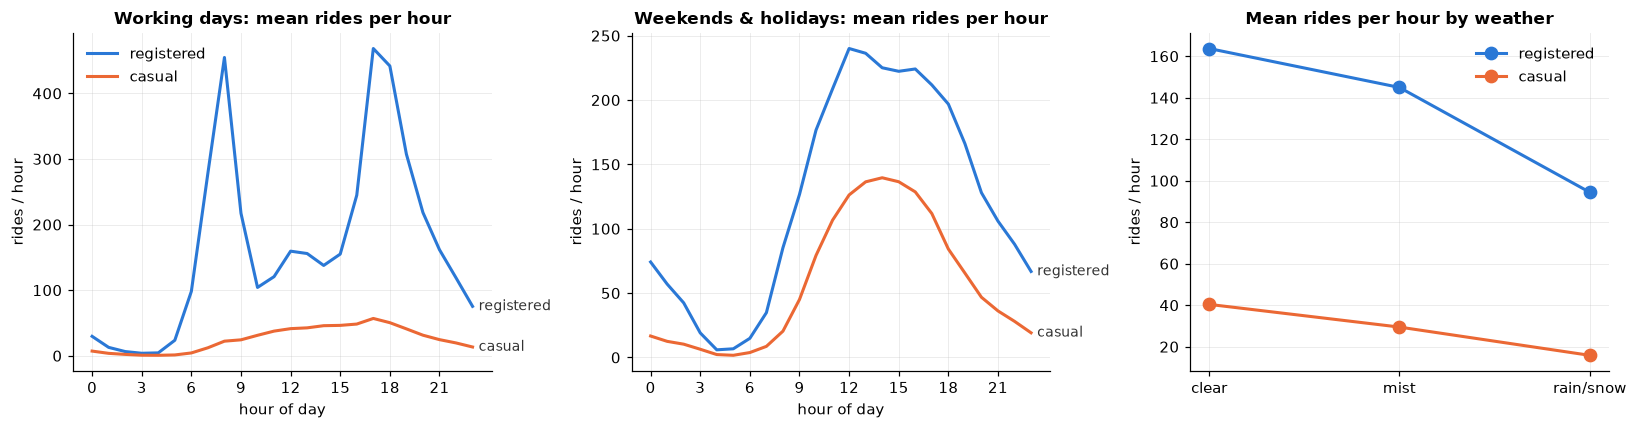

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (wd, title) in zip(axes[:2], [(1, 'Working days'), (0, 'Weekends & holidays')]):
    prof = h[h.workingday == wd].groupby('hr')[['registered', 'casual']].mean()
    for c in ['registered', 'casual']:
        ax.plot(prof.index, prof[c], color=COL[c], label=c)
        ax.annotate(c, (prof.index[-1], prof[c].iloc[-1]), xytext=(4, 0), textcoords='offset points', color='#333', fontsize=9, va='center')
    ax.set(title=f'{title}: mean rides per hour', xlabel='hour of day', ylabel='rides / hour', xticks=range(0, 24, 3))
axes[0].legend(frameon=False, loc='upper left')

ax = axes[2]
for c in ['registered', 'casual']:
    vals = [h.loc[h.weathersit == w, c].mean() for w in (1, 2, 3)]
    ax.plot([1, 2, 3], vals, marker='o', ms=8, color=COL[c], label=c)
ax.set(title='Mean rides per hour by weather', xticks=[1, 2, 3], xticklabels=['clear', 'mist', 'rain/snow'], ylabel='rides / hour')
ax.legend(frameon=False)
savefig('fig02_profiles_weather')

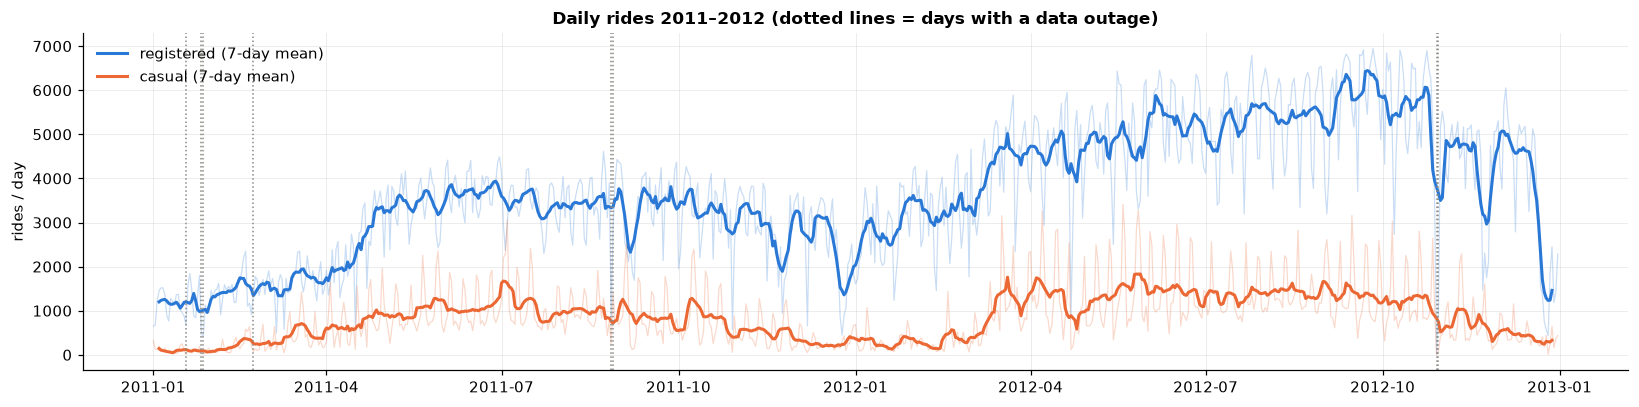

In [11]:
fig, ax = plt.subplots(figsize=(15, 3.8))
for c in ['registered', 'casual']:
    ax.plot(daily.index, daily[c], color=COL[c], alpha=0.25, lw=0.8)
    ax.plot(daily.index, daily[c].rolling(7, center=True).mean(), color=COL[c], label=f'{c} (7-day mean)')
for d in daily.index[daily.outage_hours > 0]:
    ax.axvline(d, color=C_GREY, ls=':', lw=1)
ax.set(title='Daily rides 2011–2012 (dotted lines = days with a data outage)', ylabel='rides / day')
ax.legend(frameon=False, loc='upper left')
savefig('fig01_daily_timeseries')

**Reading (for the report).**
- Registered riders have the **two-peak commuter shape** (08:00 and 17–18:00) on working days. Casual riders have a **single afternoon hump** that is far larger at weekends. These are two different populations, which justifies analysing them **separately** throughout.
- Rain/snow hours have far fewer riders than clear hours, and the relative drop is **bigger for casual riders** (see the % table). This raw comparison is confounded by hour of day and season; Sections 6–7 control for both.
- There is a strong upward trend from 2011 to 2012 (the system grew), so every "normal demand" baseline must be computed **per year and month**.

## 3 · Anomaly detection (daily level) and external evidence

**Why.** Task 1 asks us to find anomalies with *different unsupervised methods* and to justify them with external information. We detect anomalies in **demand** (relative to what is normal for that year, month and day type) and then *explain* them with the weather in the data and with news archives. This also shows *why the research question matters*: most extreme demand drops turn out to be weather events.

**Method choice.** We use one detector from each family in the lecture's taxonomy [Lecture: Anomaly Detection (1) – Slide 20], because each family defines "anomaly" differently [Slides 116–117]:
- **Robust z-score** on log demand ratio. This is univariate, the 3σ rule [Slide 27], with median/MAD instead of mean/σ so the anomalies cannot inflate their own threshold.
- **HBOS**: histogram-based and fast; it treats features as independent [Slides 42–49].
- **kNN** distance: global neighbourhood [Slides 53–64].
- **LOF**: local density; it handles regions of different density [Slides 65–90].

Each detector flags its **top 2 %** (≈ 15 days) [Slide 19: output = rank / top-N %]. A day flagged by ≥ 2 detectors is a *consensus anomaly*.

In [12]:
from pyod.models.hbos import HBOS
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from sklearn.preprocessing import StandardScaler

grp = daily.groupby(['yr', 'mnth', 'workingday'])
for c in ['casual', 'registered', 'cnt']:
    daily[f'exp_{c}'] = grp[c].transform('median')
    daily[f'lr_{c}'] = np.log((daily[c] + 1) / (daily[f'exp_{c}'] + 1))   # log ratio: 0 = normal, -0.69 = half of normal

FEATS = ['lr_casual', 'lr_registered', 'casual_share']
Xs = StandardScaler().fit_transform(daily[FEATS])
CONTAM = 0.02
N_TOP = int(round(CONTAM * len(daily)))

scores = pd.DataFrame(index=daily.index)
z = (daily.lr_cnt - daily.lr_cnt.median()) / stats.median_abs_deviation(daily.lr_cnt, scale='normal')
scores['robust_z'] = z.abs()
for name, model in {'HBOS': HBOS(n_bins=20, contamination=CONTAM),
                    'kNN': KNN(n_neighbors=10, contamination=CONTAM),
                    'LOF': LOF(n_neighbors=20, contamination=CONTAM)}.items():
    model.fit(Xs)
    scores[name] = model.decision_scores_

flags = scores.rank(ascending=False).le(N_TOP)
daily['votes'] = flags.sum(axis=1)
print(f'each detector flags its top {N_TOP} days | |robust z| > 3 (classic 3-sigma rule): {(scores.robust_z > 3).sum()} days')
print('days by number of detectors agreeing:', daily.votes.value_counts().sort_index().to_dict())

jac = pd.DataFrame({a: {b: (flags[a] & flags[b]).sum() / (flags[a] | flags[b]).sum() for b in flags} for a in flags})
print('Jaccard overlap between detectors:')
jac.round(2)

each detector flags its top 15 days | |robust z| > 3 (classic 3-sigma rule): 73 days
days by number of detectors agreeing: {0: 696, 1: 20, 2: 7, 3: 6, 4: 2}
Jaccard overlap between detectors:


,robust_z,HBOS,kNN,LOF
robust_z,1.00,0.25,0.58,0.15
HBOS,0.25,1.00,0.25,0.15
kNN,0.58,0.25,1.00,0.25
LOF,0.15,0.15,0.25,1.00


In [13]:
def in_data_reason(r):
    if r.outage_hours > 0:
        return 'system/data outage (storm)'
    if r.lr_cnt > 0:
        return 'unusually HIGH demand'
    if r.bad_hours >= 4 or r.weathersit == 3:
        return f'bad weather in data ({r.bad_hours} h rain/snow)'
    if r.holiday == 1:
        return 'public holiday'
    return 'not explained by the data'

anom = daily[daily.votes >= 2].copy()
anom['reason_in_data'] = anom.apply(in_data_reason, axis=1)
anom['weekday_name'] = anom.index.day_name()
cols = ['weekday_name', 'votes', 'cnt', 'exp_cnt', 'lr_cnt', 'casual_share', 'weathersit', 'bad_hours', 'temp_c', 'hum_pct', 'wind_kmh', 'holiday', 'reason_in_data']
anom.sort_values('lr_cnt')[cols]

,weekday_name,votes,cnt,exp_cnt,lr_cnt,casual_share,weathersit,bad_hours,temp_c,hum_pct,wind_kmh,holiday,reason_in_data
dteday,,,,,,,,,,,,,
2012-10-29,Monday,4,22.0,7343.5,-5.766,0.091,3,24,12.680,88.000,23.999,0,system/data outage (storm)
2012-12-26,Wednesday,4,441.0,5218.5,-2.469,0.020,3,16,3.437,82.333,21.209,0,bad weather in data (16 h rain/snow)
2011-10-29,Saturday,3,627.0,4381.0,-1.943,0.091,3,19,3.946,88.250,23.542,0,bad weather in data (19 h rain/snow)
2012-10-30,Tuesday,3,1096.0,7343.5,-1.901,0.079,2,19,10.056,85.500,19.541,0,system/data outage (storm)
2012-04-22,Sunday,3,1027.0,6337.0,-1.819,0.117,3,17,10.643,83.542,23.085,0,bad weather in data (17 h rain/snow)
2012-12-24,Monday,2,920.0,5218.5,-1.735,0.189,2,9,2.810,78.958,4.959,0,bad weather in data (9 h rain/snow)
2011-12-07,Wednesday,2,705.0,3322.0,-1.549,0.071,3,21,11.270,97.042,17.834,0,bad weather in data (21 h rain/snow)
2011-04-16,Saturday,2,795.0,3187.5,-1.388,0.152,3,12,12.249,88.833,22.834,0,bad weather in data (12 h rain/snow)
2011-03-06,Sunday,3,605.0,2274.5,-1.323,0.188,2,9,9.782,94.542,23.042,0,bad weather in data (9 h rain/snow)


### 3.1 External evidence for the consensus anomalies

Each date was checked against news archives and weather records (see the `source` column; full links are in `tasks.md`). An LLM was used to *suggest* candidate events, and every suggestion was checked against the source before it went into the table (documented in Supplementary A).

In [14]:
EXTERNAL = {   # date: (event, source); full URLs in tasks.md § Sources
    '2012-10-29': ('Hurricane Sandy: Capital Bikeshare closed from 01:00 for ~36 h', 'ARLnow; WTOP (Oct 2012)'),
    '2012-10-30': ('Hurricane Sandy: system reopened Tuesday afternoon', 'ARLnow (Oct 2012)'),
    '2011-08-27': ('Hurricane Irene: Capital Bikeshare closed at 18:00', 'DCist; Washington Times (27 Aug 2011)'),
    '2011-01-27': ('day after 26-Jan thundersnow storm (~5" snow in evening rush, ~300k without power)', 'NOAA WPC storm review; NPR; AP'),
    '2011-10-29': ("2011 Halloween nor'easter (rain/snow mix, trace of snow in D.C.)", "NASA/PhysOrg; Wikipedia '2011 Halloween nor'easter'"),
    '2012-12-26': ('late-Dec 2012 storm complex: first wintry mix of the season in D.C.', 'NOAA WPC; Wikipedia'),
    '2012-04-22': ('late-April 2012 coastal storm: > 1" rain in D.C. region, MLB game postponed', 'NWS LWX monthly summary; AP'),
    '2011-04-16': ('severe storms: 4 tornadoes MD/VA, 58 mph gust at DCA, flooding at Jefferson Memorial', 'NWS LWX event page 2011-04-16'),
    '2012-12-24': ('Christmas Eve: federal offices closed by executive order (21 Dec 2012)', 'GovExec; FedSmith (Dec 2012)'),
    '2011-12-25': ('Christmas Day (a Sunday; the holiday flag is on the observed Monday 26 Dec)', 'U.S. OPM holiday calendar'),
    '2012-12-25': ('Christmas Day', 'U.S. OPM holiday calendar'),
    '2012-11-23': ('day after Thanksgiving: not a holiday in the data, but casual share 41 % = weekend-like', 'calendar + in-data casual share'),
    '2011-11-25': ('day after Thanksgiving: not a holiday in the data, but casual share 39 % = weekend-like', 'calendar + in-data casual share'),
}
anom['external_event'] = [EXTERNAL.get(str(d.date()), ('', ''))[0] for d in anom.index]
anom['source'] = [EXTERNAL.get(str(d.date()), ('', ''))[1] for d in anom.index]
explained = (anom.reason_in_data != 'not explained by the data') | anom.external_event.ne('')
print(f'consensus anomalies: {len(anom)} | explained by data or external evidence: {explained.sum()} ({explained.mean():.0%})')
anom.sort_values('lr_cnt')[['weekday_name', 'cnt', 'exp_cnt', 'reason_in_data', 'external_event', 'source']]

consensus anomalies: 15 | explained by data or external evidence: 15 (100%)


,weekday_name,cnt,exp_cnt,reason_in_data,external_event,source
dteday,,,,,,
2012-10-29,Monday,22.0,7343.5,system/data outage (storm),Hurricane Sandy: Capital Bikeshare closed from 01:00 for ~36 h,ARLnow; WTOP (Oct 2012)
2012-12-26,Wednesday,441.0,5218.5,bad weather in data (16 h rain/snow),late-Dec 2012 storm complex: first wintry mix of the season in D.C.,NOAA WPC; Wikipedia
2011-10-29,Saturday,627.0,4381.0,bad weather in data (19 h rain/snow),"2011 Halloween nor'easter (rain/snow mix, trace of snow in D.C.)",NASA/PhysOrg; Wikipedia '2011 Halloween nor'easter'
2012-10-30,Tuesday,1096.0,7343.5,system/data outage (storm),Hurricane Sandy: system reopened Tuesday afternoon,ARLnow (Oct 2012)
2012-04-22,Sunday,1027.0,6337.0,bad weather in data (17 h rain/snow),"late-April 2012 coastal storm: > 1"" rain in D.C. region, MLB game postponed",NWS LWX monthly summary; AP
2012-12-24,Monday,920.0,5218.5,bad weather in data (9 h rain/snow),Christmas Eve: federal offices closed by executive order (21 Dec 2012),GovExec; FedSmith (Dec 2012)
2011-12-07,Wednesday,705.0,3322.0,bad weather in data (21 h rain/snow),,
2011-04-16,Saturday,795.0,3187.5,bad weather in data (12 h rain/snow),"severe storms: 4 tornadoes MD/VA, 58 mph gust at DCA, flooding at Jefferson Memorial",NWS LWX event page 2011-04-16
2011-03-06,Sunday,605.0,2274.5,bad weather in data (9 h rain/snow),,


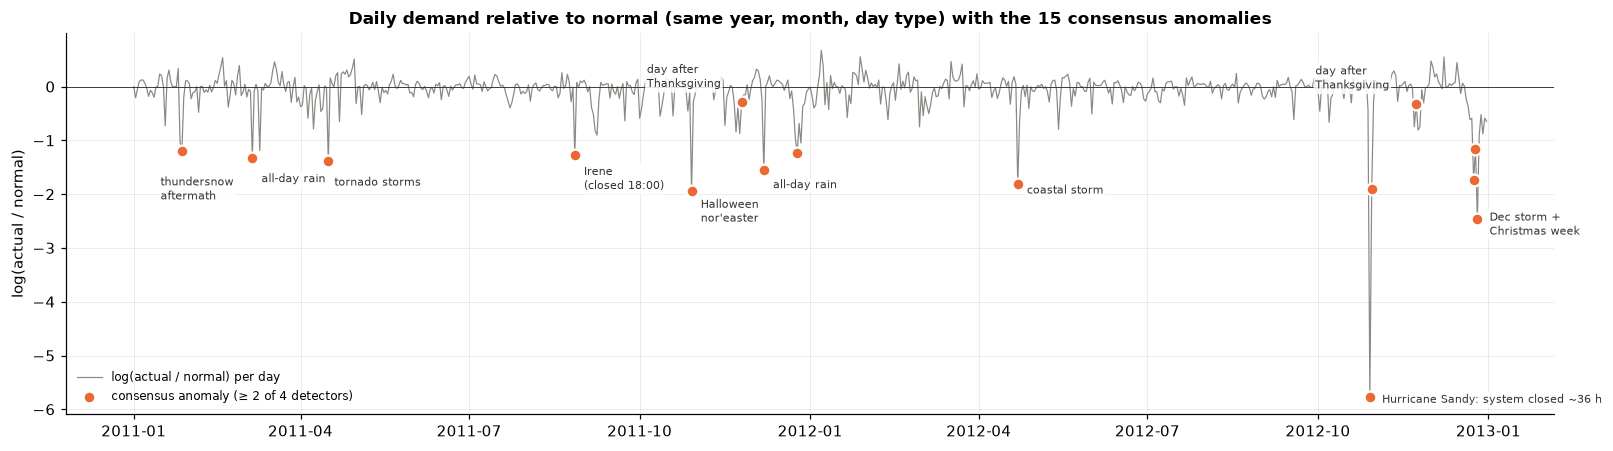

In [15]:
fig, ax = plt.subplots(figsize=(15, 4.2))
ax.plot(daily.index, daily.lr_cnt, color=C_GREY, lw=0.8, label='log(actual / normal) per day')
ax.scatter(anom.index, anom.lr_cnt, s=60, color=C_CAS, zorder=3, edgecolor='white', linewidth=1.5, label='consensus anomaly (≥ 2 of 4 detectors)')
SHORT = [  # (date, short label, text offset in points)
    ('2011-01-27', 'thundersnow\naftermath', (-14, -32)), ('2011-03-06', 'all-day rain', (6, -16)),
    ('2011-04-16', 'tornado storms', (4, -16)), ('2011-08-27', 'Irene\n(closed 18:00)', (6, -22)),
    ("2011-10-29", "Halloween\nnor'easter", (6, -20)), ('2011-11-25', 'day after\nThanksgiving', (-62, 10)),
    ('2011-12-07', 'all-day rain', (6, -12)), ('2012-04-22', 'coastal storm', (6, -6)),
    ('2012-10-29', 'Hurricane Sandy: system closed ~36 h', (8, -4)), ('2012-11-23', 'day after\nThanksgiving', (-66, 10)),
    ('2012-12-26', 'Dec storm +\nChristmas week', (8, -10)),
]
for d, lab, off in SHORT:
    ax.annotate(lab, (pd.Timestamp(d), daily.loc[d, 'lr_cnt']), xytext=off, textcoords='offset points', fontsize=7.5, color='#333',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
ax.axhline(0, color='#333', lw=0.6)
ax.set(title='Daily demand relative to normal (same year, month, day type) with the 15 consensus anomalies', ylabel='log(actual / normal)')
ax.legend(frameon=False, loc='lower left', fontsize=8)
savefig('fig03_anomalies')

**Reading.**
- The four detectors agree only partly. Only 2 days are flagged by all four (Sandy, 29 Oct 2012, and the 26 Dec 2012 storm). The robust z-score and kNN overlap most (Jaccard 0.58). LOF overlaps least (0.15–0.25) because it looks for *locally* unusual combinations, such as a normal total with an odd casual share. That is why we use a vote and not a single method [Slides 116–117].
- **All 15 consensus anomalies are low-demand days, and all 15 can be explained.**
  - **10 are weather or storm days**: Sandy, Irene, the Jan-2011 thundersnow, the Halloween 2011 nor'easter, the April 2011 tornado storms, and others. 4 of them include a confirmed system shutdown.
  - **5 are calendar days the `holiday` flag misses**: Christmas Day 2011 (a Sunday, so the flag sits on the observed Monday), Christmas Eve 2012 (federal offices closed by executive order), and both *days after Thanksgiving*. On those two days the casual share is about 40 %, like a weekend.
- Two of the weather days (7 Dec 2011, 6 Mar 2011) are explained by the in-data weather only (21 h and 9 h of rain); no external source was searched for them.
- **Spin-off for feature engineering:** a `bridge_day` flag (Christmas Eve, day after Thanksgiving) would fix a real gap in the dataset's holiday column.

**Decision that follows from this section.** Days with a **data outage** are *noise* for our question: they show missing supply or data, not low demand [Lecture: Anomaly Detection (1) – Slide 18, noise vs meaningful anomaly]. They are excluded from the recovery analysis. Every other low-demand anomaly is **kept**, because it is exactly the phenomenon we study: bad weather, and what happens after it.

## 4 · Feature engineering: weather episodes and "hours since bad weather"

**Why.** The raw data only says *what the weather is now*. Our question is about *what the weather was*, so we have to **change the representation** of the data from "independent hours" to "time since an event". The course learning outcomes name this skill explicitly (change of data representation) [Lecture: Introduction / course goals – Slide ?]. These features are the core of the project's creativity score.

| Feature | Definition | Why it is needed |
|---|---|---|
| `bad` | weathersit = 3 (light/heavy rain or snow) | defines the event |
| `episode` | maximal run of consecutive bad hours | one rain shower = one event, not N rows |
| `h_after` | hours since the episode ended (0 = first dry hour) | **the recovery clock** |
| `after_bin` | `h_after` binned 0, 1, 2, 3, 4–6, 7–12, 13–24, >24 h | lets a linear model learn any recovery shape |
| `prev_dur`, `prev_type` | length and rain-vs-snow type of the last episode | does a long storm leave a longer hangover? |
| `bad_last6/24` | bad hours in the previous 6 / 24 h | accumulated wetness (puddles, wet seats) |
| `snow proxy` | mean temperature during the episode < 2 °C | weathersit 3 mixes light rain and light snow |
| `exp_*`, `ratio_*` | normal demand for the same year, month, day type and hour; actual ÷ normal | puts 3 a.m. and 5 p.m. on the same scale |
| `daypart`, `comfort_gap` | AM peak / midday / PM peak / evening / night; atemp − temp | commuter timing; humid "sticky" air after rain |

In [16]:
df['bad'] = df.weathersit.eq(3)
run = df.bad.ne(df.bad.shift()).cumsum()
df['episode'] = run.where(df.bad)

ep = (df[df.bad].reset_index().groupby('episode')
      .agg(start=('ts', 'min'), last_bad=('ts', 'max'), dur_h=('ts', 'size'),
           mean_temp=('temp_c', 'mean'), outage=('outage', 'max')))
ep['end'] = ep.last_bad + pd.Timedelta('1h')                      # first dry hour
ep['dry_after_h'] = ((ep.start.shift(-1) - ep.end) / pd.Timedelta('1h')).fillna(np.inf)
ep['type'] = np.where(ep.mean_temp < 2, 'snow/ice', 'rain')

last_bad = pd.Series(df.index.where(df.bad), index=df.index).ffill()
df['h_after'] = ((df.index.to_series() - last_bad) / pd.Timedelta('1h') - 1).where(~df.bad)
df['prev_ep'] = df.episode.ffill().where(~df.bad)
df['prev_dur'] = df.prev_ep.map(ep.dur_h)
df['prev_type'] = df.prev_ep.map(ep.type)
bad_int = df.bad.astype(int).shift(1, fill_value=0)
df['bad_last6'] = bad_int.rolling(6, min_periods=1).sum()
df['bad_last24'] = bad_int.rolling(24, min_periods=1).sum()

BIN_EDGES = [-0.5, 0.5, 1.5, 2.5, 3.5, 6.5, 12.5, 24.5, np.inf]
BIN_LABELS = ['0h', '1h', '2h', '3h', '4-6h', '7-12h', '13-24h', '>24h']
AFTER_ORDER = ['bad now'] + BIN_LABELS
df['after_bin'] = pd.cut(df.h_after.fillna(np.inf), BIN_EDGES, labels=BIN_LABELS).astype(str)
df.loc[df.bad, 'after_bin'] = 'bad now'

df['daypart'] = pd.cut(df.hr, [-1, 5, 9, 15, 19, 23], labels=['night', 'AM peak', 'midday', 'PM peak', 'evening']).astype(str)
df['comfort_gap'] = df.atemp_c - df.temp_c
df['casual_share'] = df.casual / df.cnt.where(df.cnt > 0)

# expected ("normal") demand: median of the same year, month, day type and hour,
# taken only from hours that are dry, > 24 h after bad weather, not a holiday and not an outage
KEYS = ['yr', 'mnth', 'workingday', 'hr']
normal = ~df.bad & df.after_bin.eq('>24h') & ~df.outage & df.holiday.eq(0)
for c in ['casual', 'registered', 'cnt']:
    med = df[normal].groupby(KEYS)[c].median()
    fallback = df[~df.bad & ~df.outage].groupby(KEYS)[c].median()
    key = pd.MultiIndex.from_frame(df[KEYS])
    df[f'exp_{c}'] = pd.Series(med.reindex(key).values, index=df.index).fillna(pd.Series(fallback.reindex(key).values, index=df.index))
    df[f'ratio_{c}'] = (df[c] + 1) / (df[f'exp_{c}'] + 1)
print('hours that needed the fallback baseline:',
      int(pd.Series(df[normal].groupby(KEYS).cnt.median().reindex(pd.MultiIndex.from_frame(df[KEYS])).values).isna().sum()))
print('hours per after_bin:', df.after_bin.value_counts().reindex(AFTER_ORDER).to_dict())

hours that needed the fallback baseline: 48
hours per after_bin: {'bad now': 1526, '0h': 492, '1h': 398, '2h': 351, '3h': 328, '4-6h': 866, '7-12h': 1426, '13-24h': 2251, '>24h': 9906}


492 bad-weather episodes | duration: median 2 h, mean 3.1 h, max 51 h
type: {'rain': 470, 'snow/ice': 22} | episodes touching an outage: 5


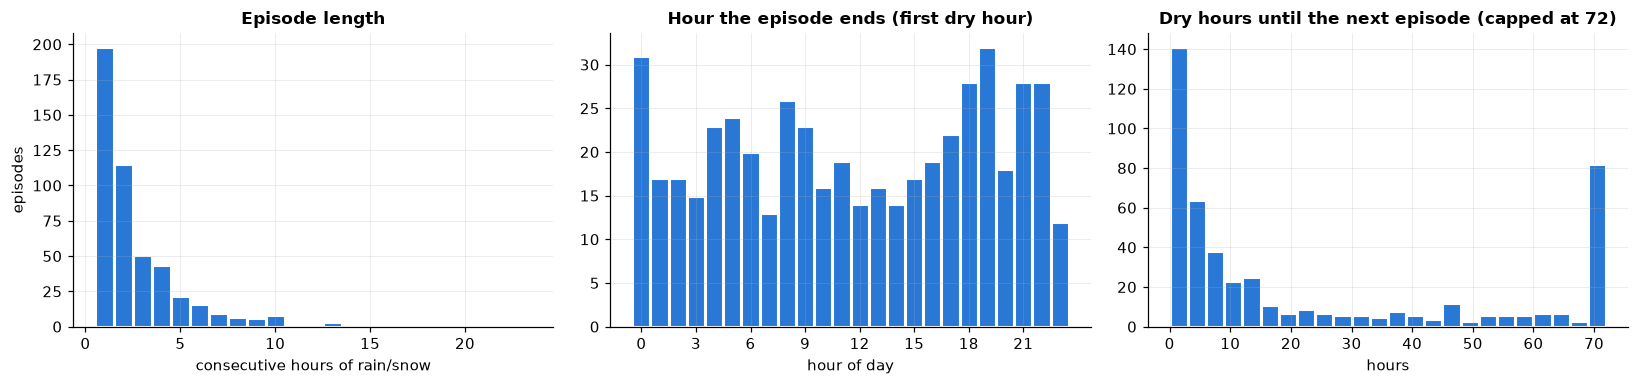

In [17]:
print(f'{len(ep)} bad-weather episodes | duration: median {ep.dur_h.median():.0f} h, mean {ep.dur_h.mean():.1f} h, max {ep.dur_h.max()} h')
print('type:', ep.type.value_counts().to_dict(), '| episodes touching an outage:', int(ep.outage.sum()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(ep.dur_h, bins=np.arange(0.5, 24.5, 1), color=C_REG, edgecolor='white', linewidth=2)
axes[0].set(title='Episode length', xlabel='consecutive hours of rain/snow', ylabel='episodes')
axes[1].hist(ep.end.dt.hour, bins=np.arange(-0.5, 24.5, 1), color=C_REG, edgecolor='white', linewidth=2)
axes[1].set(title='Hour the episode ends (first dry hour)', xlabel='hour of day', xticks=range(0, 24, 3))
axes[2].hist(ep.dry_after_h.clip(upper=72), bins=np.arange(0, 74, 3), color=C_REG, edgecolor='white', linewidth=2)
axes[2].set(title='Dry hours until the next episode (capped at 72)', xlabel='hours')
savefig('fig04_episodes')

## 5 · Dimension reduction and visualisation

**Why.**
- **(a)** A day has 24 hourly values. PCA compresses the *shape* of the day into 2 numbers and shows whether days really split into commuter-shaped and leisure-shaped days, and where rainy days fall. We divide each day by its total (shape, not volume) because volume is dominated by season and trend. We do *not* standardise the 24 columns, because that would blow up the noise in the near-empty night hours.
- **(b)** PCA on the per-episode **recovery curves** shows whether recoveries differ mainly in *depth* (how far demand falls) or in *speed* (how fast it comes back).

**Source.** PCA [Lecture: Dimension reduction – Slide ?]. Lab 1 used PCA before clustering.

explained variance ratio (PC1..PC5): [0.738 0.107 0.045 0.024 0.017] | PC1+PC2 = 0.845
corr(PC1, casual share) = -0.74


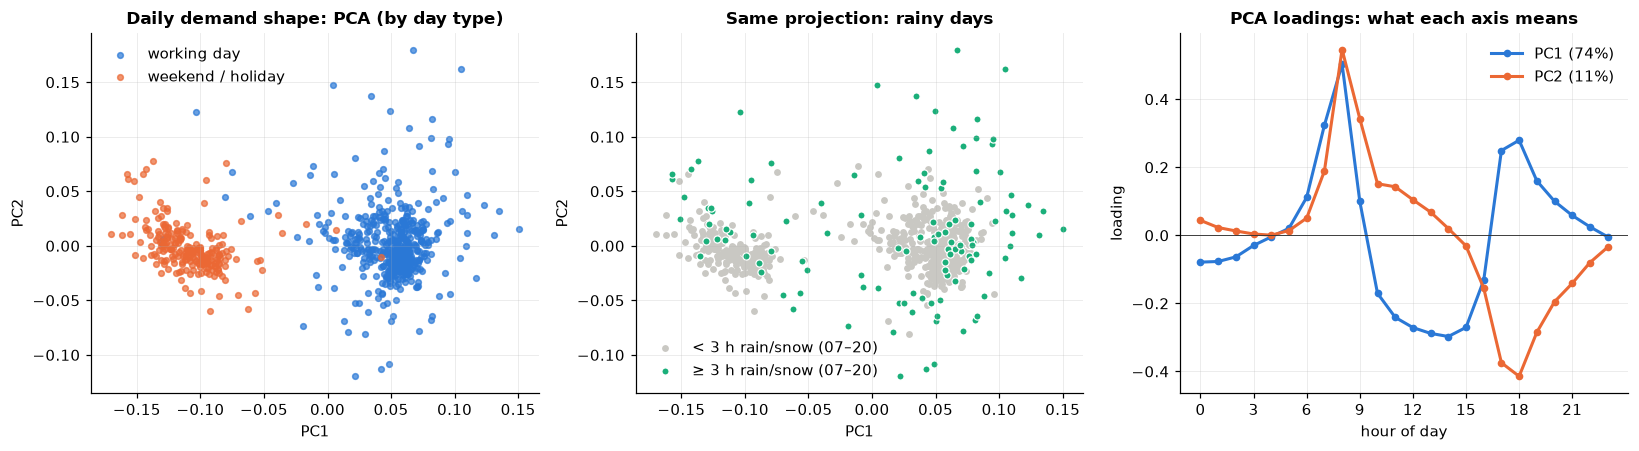

In [18]:
from sklearn.decomposition import PCA

prof = df[~df.outage].pivot_table(index='dteday', columns='hr', values='cnt', aggfunc='sum').dropna()
shape = prof.div(prof.sum(axis=1), axis=0)
pca = PCA(n_components=5, random_state=RANDOM_STATE).fit(shape)
Z = pca.transform(shape)
meta = daily.loc[shape.index]
day_rain = df[df.hr.between(7, 20)].groupby('dteday').bad.sum().reindex(shape.index) >= 3
print('explained variance ratio (PC1..PC5):', pca.explained_variance_ratio_.round(3), '| PC1+PC2 =', pca.explained_variance_ratio_[:2].sum().round(3))
print(f'corr(PC1, casual share) = {np.corrcoef(Z[:, 0], meta.casual_share)[0, 1]:.2f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
for wd, c, lab in [(1, C_REG, 'working day'), (0, C_CAS, 'weekend / holiday')]:
    m = meta.workingday.values == wd
    ax.scatter(Z[m, 0], Z[m, 1], s=14, color=c, alpha=0.7, label=lab)
ax.set(title='Daily demand shape: PCA (by day type)', xlabel='PC1', ylabel='PC2'); ax.legend(frameon=False)
ax = axes[1]
ax.scatter(Z[~day_rain.values, 0], Z[~day_rain.values, 1], s=12, color='#c9c8c3', label='< 3 h rain/snow (07–20)')
ax.scatter(Z[day_rain.values, 0], Z[day_rain.values, 1], s=22, color=C_3, edgecolor='white', linewidth=0.8, label='≥ 3 h rain/snow (07–20)')
ax.set(title='Same projection: rainy days', xlabel='PC1', ylabel='PC2'); ax.legend(frameon=False)
ax = axes[2]
for i, c in [(0, C_REG), (1, C_CAS)]:
    ax.plot(range(24), pca.components_[i], color=c, marker='o', ms=4, label=f'PC{i+1} ({pca.explained_variance_ratio_[i]:.0%})')
ax.axhline(0, color='#333', lw=0.6)
ax.set(title='PCA loadings: what each axis means', xlabel='hour of day', xticks=range(0, 24, 3), ylabel='loading'); ax.legend(frameon=False)
savefig('fig05_pca_day_shapes')

**Reading.**
- Two components keep 85 % of the variance of the 24-hour day shape.
- **PC1 (74 %) is the commuter-vs-leisure axis.** Its loadings are high at 08:00 and 17–18:00 and opposite in the afternoon. It correlates −0.74 with the casual share, and working days and weekends fall on opposite sides of it.
- Rainy days do not form a cluster of their own. They stay inside their day-type group, mostly at its edges (more extreme PC2). Rain distorts the shape a little, but the day type still decides it, and rain mainly changes the **volume** of the day. This is why we measure recovery *hour by hour* against a same-hour baseline, not with the daily shape.
- The two populations seen here are the reason casual and registered riders are modelled separately in §6–8.

## 6 · RQ-A: how long does demand stay low after the weather clears?

**Why this design.** We follow each rain/snow episode and measure demand **relative to normal** (`ratio = actual ÷ normal for the same year, month, day type and hour`) for the 12 hours after the first dry hour. The ratio makes 8 a.m. and 2 p.m. comparable.

| Decision | Choice | Reason |
|---|---|---|
| Which episodes | ≥ 2 h long, ≥ 6 dry hours afterwards, no outage in the window, ending 06:00–19:00 | a 1-hour flag is often a single noisy reading; a new shower would restart the clock; at night "normal" is ~0 rides, so ratios are pure noise |
| Night hours (00–05) inside the window | skipped | same reason, and no operational decision is taken at night |
| Recovered when | ratio ≥ 0.9 for **2 consecutive** daytime hours | 90 % = "within normal hour-to-hour noise"; 2 hours stops one lucky hour from counting |
| Not recovered within 12 h | treated as > 12 h (censored) | we do not invent a recovery time |
| Casual vs registered test | **paired** Wilcoxon signed-rank (same episodes), bootstrap CI | recovery times are skewed integers, so a t-test is not appropriate; pairing removes the episode-to-episode differences |

**Source.** Hypothesis testing and evaluation [Lecture: Evaluation – Slide ?]; Wilcoxon signed-rank test (Wilcoxon, 1945).

In [19]:
MIN_DUR, MIN_DRY, WINDOW, THRESH = 2, 6, 12, 0.9
ep['window_outage'] = [df.outage.loc[e.start:e.end + pd.Timedelta(hours=WINDOW)].any() for e in ep.itertuples()]
sel = ep[(ep.dur_h >= MIN_DUR) & (ep.dry_after_h >= MIN_DRY) & ~ep.window_outage & ep.end.dt.hour.between(6, 19)].copy()
print(f'episodes used: {len(sel)} of {len(ep)} | rain: {(sel.type == "rain").sum()}, snow/ice: {(sel.type == "snow/ice").sum()}')

K = np.arange(WINDOW + 1)

def curve(e, col):
    seg = df.reindex(pd.date_range(e.end, periods=WINDOW + 1, freq='h'))
    r = seg[f'ratio_{col}'].where(seg.hr >= 6)          # skip night hours
    r[seg.bad.cummax().values] = np.nan                 # stop if bad weather returns
    return r.values

curves = {c: pd.DataFrame([curve(e, c) for e in sel.itertuples()], index=sel.index, columns=K) for c in ['registered', 'casual']}

def recovery_time(row):
    v = row.dropna()
    ok = (v >= THRESH).values
    for i in range(len(v) - 1):
        if ok[i] and ok[i + 1]:
            return v.index[i]
    return np.nan                                        # not recovered inside the window

rt = pd.DataFrame({c: curves[c].apply(recovery_time, axis=1) for c in curves})
summary = pd.DataFrame({c: {
    'median ratio at 0 h': curves[c][0].median(),
    'median ratio at 2 h': curves[c][2].median(),
    'median recovery time (h)': rt[c].fillna(WINDOW + 1).median(),
    'recovered within 1 h': (rt[c] <= 1).mean(),
    'recovered within 3 h': (rt[c] <= 3).mean(),
    'recovered within 6 h': (rt[c] <= 6).mean(),
    'not recovered in 12 h': rt[c].isna().mean()} for c in rt}).T
summary

episodes used: 93 of 492 | rain: 87, snow/ice: 6


,median ratio at 0 h,median ratio at 2 h,median recovery time (h),recovered within 1 h,recovered within 3 h,recovered within 6 h,not recovered in 12 h
registered,0.708,0.863,3.0,0.333,0.527,0.688,0.226
casual,0.535,0.574,11.0,0.129,0.301,0.430,0.484


In [20]:
both = rt.fillna(WINDOW + 1)
diff = both.casual - both.registered
w = stats.wilcoxon(both.casual, both.registered, alternative='greater')
boot_med = np.array([np.median(rng.choice(diff.values, len(diff))) for _ in range(5000)])
boot_mean = np.array([np.mean(rng.choice(diff.values, len(diff))) for _ in range(5000)])
print(f'casual minus registered recovery time: median {diff.median():.1f} h (95% bootstrap CI {np.percentile(boot_med, 2.5):.1f} to {np.percentile(boot_med, 97.5):.1f}), '
      f'mean {diff.mean():.2f} h (95% CI {np.percentile(boot_mean, 2.5):.2f} to {np.percentile(boot_mean, 97.5):.2f})')
print(f'casual slower in {(diff > 0).mean():.0%} of episodes, equal in {(diff == 0).mean():.0%}, faster in {(diff < 0).mean():.0%}')
print(f'paired Wilcoxon signed-rank (H1: casual takes longer): W = {w.statistic:.0f}, p = {w.pvalue:.2g}')

casual minus registered recovery time: median 2.0 h (95% bootstrap CI 0.0 to 3.0), mean 2.98 h (95% CI 1.80 to 4.13)
casual slower in 56% of episodes, equal in 32%, faster in 12%
paired Wilcoxon signed-rank (H1: casual takes longer): W = 1688, p = 1.6e-06


In [21]:
# sensitivity: does the conclusion depend on our two arbitrary choices (threshold, minimum episode length)?
rows = []
for th in [0.85, 0.90, 0.95]:
    for md_ in [1, 2, 3]:
        s = ep[(ep.dur_h >= md_) & (ep.dry_after_h >= MIN_DRY) & ~ep.window_outage & ep.end.dt.hour.between(6, 19)]
        cv_ = {c: pd.DataFrame([curve(e, c) for e in s.itertuples()], index=s.index, columns=K) for c in ['registered', 'casual']}
        THRESH = th                                              # recovery_time() reads the global threshold
        r_ = pd.DataFrame({c: cv_[c].apply(recovery_time, axis=1) for c in cv_}).fillna(WINDOW + 1)
        rows.append([th, md_, len(s), r_.registered.median(), r_.casual.median(),
                     stats.wilcoxon(r_.casual, r_.registered, alternative='greater').pvalue])
THRESH = 0.9
sens = pd.DataFrame(rows, columns=['threshold', 'min episode h', 'episodes', 'registered median h', 'casual median h', 'Wilcoxon p'])
print(f'casual slower than registered in {(sens["casual median h"] > sens["registered median h"]).sum()} of {len(sens)} settings; max p = {sens["Wilcoxon p"].max():.1e}')
sens

casual slower than registered in 9 of 9 settings; max p = 1.8e-03


,threshold,min episode h,episodes,registered median h,casual median h,Wilcoxon p
0,0.85,1,160,1.0,6.0,3.882e-13
1,0.85,2,93,2.0,10.0,6.262e-09
2,0.85,3,53,2.0,13.0,1.832e-06
3,0.90,1,160,2.0,8.0,8.032e-11
4,0.90,2,93,3.0,11.0,1.567e-06
5,0.90,3,53,3.0,13.0,1.253e-04
6,0.95,1,160,3.5,12.0,2.256e-08
7,0.95,2,93,5.0,13.0,2.854e-04
8,0.95,3,53,5.0,13.0,1.770e-03


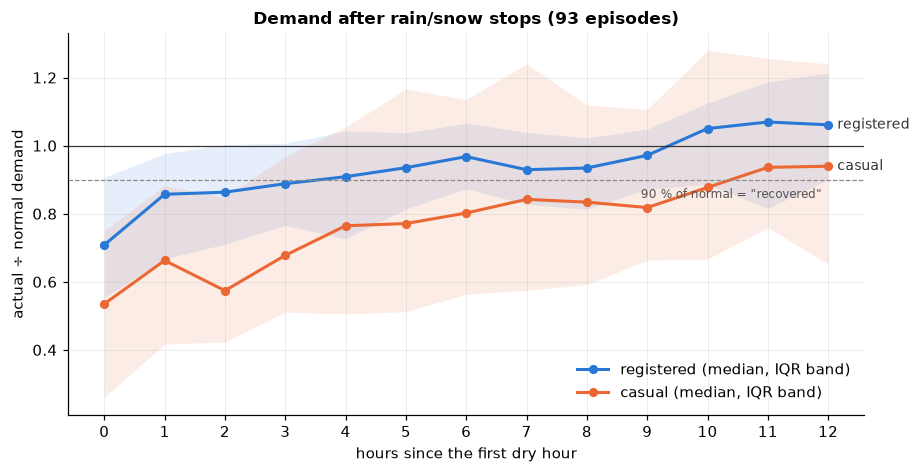

In [22]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for c in ['registered', 'casual']:
    q = curves[c].quantile([0.25, 0.5, 0.75])
    ax.fill_between(K, q.loc[0.25], q.loc[0.75], color=COL[c], alpha=0.12, linewidth=0)
    ax.plot(K, q.loc[0.5], color=COL[c], marker='o', ms=5, label=f'{c} (median, IQR band)')
    ax.annotate(c, (K[-1], q.loc[0.5].iloc[-1]), xytext=(6, 0), textcoords='offset points', fontsize=9, color='#333', va='center')
ax.axhline(1.0, color='#333', lw=0.8)
ax.axhline(THRESH, color=C_GREY, lw=0.8, ls='--')
ax.annotate('90 % of normal = "recovered"', (K[-1], THRESH), xytext=(-4, -12), textcoords='offset points', ha='right', fontsize=8, color='#555')
ax.set(title=f'Demand after rain/snow stops ({len(sel)} episodes)', xlabel='hours since the first dry hour', ylabel='actual ÷ normal demand', xticks=K)
ax.legend(frameon=False, loc='lower right')
savefig('fig06_recovery_curves')

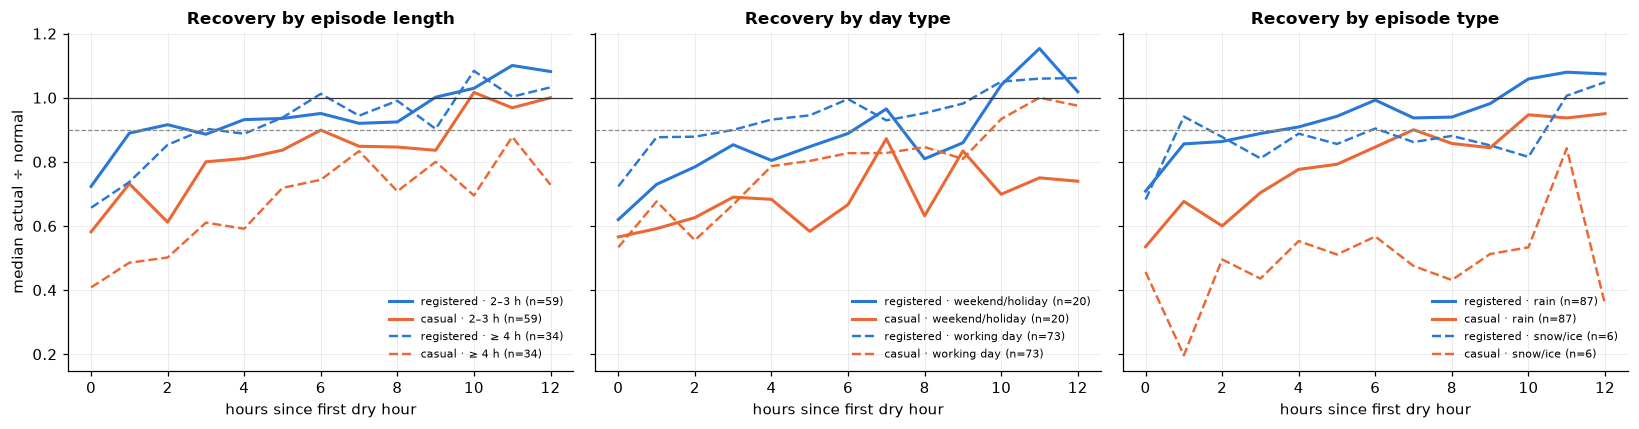

,split,group,rider,episodes,median recovery h,median ratio at 0 h
0,episode length,2–3 h,registered,59,3.0,0.723
1,episode length,2–3 h,casual,59,6.0,0.581
2,episode length,≥ 4 h,registered,34,3.0,0.657
3,episode length,≥ 4 h,casual,34,13.0,0.408
4,day type,weekend/holiday,registered,20,10.5,0.620
5,day type,weekend/holiday,casual,20,13.0,0.566
6,day type,working day,registered,73,3.0,0.723
7,day type,working day,casual,73,8.0,0.533
8,episode type,rain,registered,87,3.0,0.708
9,episode type,rain,casual,87,8.0,0.535


In [23]:
splits = [
    ('episode length', np.where(sel.dur_h >= 4, '≥ 4 h', '2–3 h')),
    ('day type', np.where(df.loc[sel.end, 'workingday'].values == 1, 'working day', 'weekend/holiday')),
    ('episode type', sel.type.values),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
rows = []
for ax, (title, groups) in zip(axes, splits):
    for g, ls in zip(sorted(set(groups)), ['-', '--']):
        m = groups == g
        for c in ['registered', 'casual']:
            med = curves[c][m].median()
            ax.plot(K, med, color=COL[c], ls=ls, lw=2 if ls == '-' else 1.6, label=f'{c} · {g} (n={m.sum()})')
            rows.append([title, g, c, m.sum(), rt.loc[m, c].fillna(WINDOW + 1).median(), curves[c][m][0].median()])
    ax.axhline(1, color='#333', lw=0.8); ax.axhline(THRESH, color=C_GREY, lw=0.8, ls='--')
    ax.set(title=f'Recovery by {title}', xlabel='hours since first dry hour', xticks=K[::2])
    ax.legend(frameon=False, fontsize=7.5, loc='lower right')
axes[0].set_ylabel('median actual ÷ normal')
savefig('fig07_recovery_splits')
pd.DataFrame(rows, columns=['split', 'group', 'rider', 'episodes', 'median recovery h', 'median ratio at 0 h'])

recovery-curve PCA on 65 complete episodes | explained variance: [0.46 0.16]


,reg_0,reg_1,reg_2,reg_3,reg_4,reg_5,reg_6,cas_0,cas_1,cas_2,cas_3,cas_4,cas_5,cas_6
PC1,0.15,0.14,0.12,0.08,0.11,0.09,0.11,0.24,0.40,0.39,0.34,0.44,0.38,0.27
PC2,-0.22,-0.13,-0.04,0.02,-0.01,0.10,0.26,-0.21,-0.41,0.08,0.08,-0.29,0.33,0.65


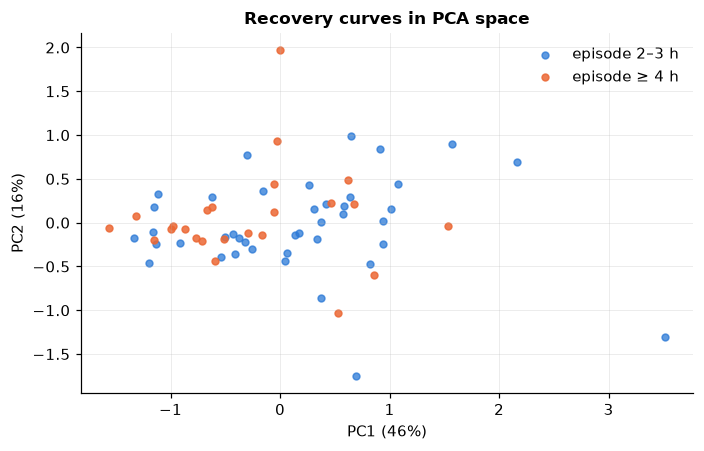

In [24]:
# (5b) PCA of recovery curves: do episodes differ in depth or in speed?
KK = list(range(0, 7))
cur = pd.concat([curves['registered'][KK].add_prefix('reg_'), curves['casual'][KK].add_prefix('cas_')], axis=1).dropna()
pca_c = PCA(n_components=2, random_state=RANDOM_STATE).fit(cur)
Zc = pca_c.transform(cur)
print(f'recovery-curve PCA on {len(cur)} complete episodes | explained variance:', pca_c.explained_variance_ratio_.round(2))
load = pd.DataFrame(pca_c.components_, columns=cur.columns, index=['PC1', 'PC2']).round(2)
display(load)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
long_ = sel.loc[cur.index, 'dur_h'] >= 4
ax.scatter(Zc[~long_.values, 0], Zc[~long_.values, 1], s=20, color=C_REG, alpha=0.75, label='episode 2–3 h')
ax.scatter(Zc[long_.values, 0], Zc[long_.values, 1], s=20, color=C_CAS, alpha=0.85, label='episode ≥ 4 h')
ax.set(title='Recovery curves in PCA space', xlabel=f'PC1 ({pca_c.explained_variance_ratio_[0]:.0%})', ylabel=f'PC2 ({pca_c.explained_variance_ratio_[1]:.0%})')
ax.legend(frameon=False)
savefig('fig08_pca_recovery_curves')

**Reading: RQ-A answer (episode view).**

*Main result.* Over 93 episodes (87 rain, 6 snow/ice), at the first dry hour registered demand is at **71 %** of normal and casual demand at **54 %**. Using "back to ≥ 90 % for 2 hours":
- Median recovery time: **registered 3 h, casual 11 h**.
- Within 3 h: 53 % of registered vs 30 % of casual episodes recover.
- Not within 12 h: 23 % of registered vs 48 % of casual episodes.

*Test.* On the *same* episodes, casual riders are slower in 56 %, equal in 32 % and faster in only 12 %. The mean gap is **+3.0 h (95 % bootstrap CI 1.8–4.1 h)** and the paired Wilcoxon test gives **p = 1.6 × 10⁻⁶**.

*Sensitivity.* The result does not depend on our two arbitrary choices. Across all 9 combinations of threshold (85/90/95 %) and minimum episode length (1/2/3 h), casual riders are slower: registered medians 1–5 h, casual medians 6–13 h, every p ≤ 0.002.

*Splits.*
- After **long episodes (≥ 4 h)** casual demand starts lower (41 % vs 58 % of normal) and recovers in 13 h vs 6 h. Registered riders recover in 3 h either way. A commute has to happen; a leisure trip can be dropped.
- On weekends, registered riders *look* slower here (median 10.5 h), but this rests on only 20 episodes, and the regression check in §7 (Model D) does **not** confirm it. We treat it as noise, not as a finding.
- Snow/ice episodes look slower for casual riders (13 h), but with n = 6 this is only a hint.

*Recovery-curve PCA.*
- PC1 (46 %) loads mainly on the casual ratios, so episodes differ first in **how deep casual demand falls**.
- PC2 (16 %) contrasts the first hours with hours 5–6, so it captures **recovery speed**.

*Limitation.* The baseline is a monthly median. It does not control for the fact that the air is still humid right after rain. §7 does.

## 7 · RQ-B: regression on lagged weather. Is the "hangover" real once we control for the current weather?

**Why.** Section 6 compares against a monthly median. But after rain the air is often cooler and more humid, so demand could be low *because of the current weather*, not because of the rain that just ended. Regression separates the two: we add **lagged weather** (the `after_bin` recovery clock) on top of the **current** weather and calendar.

- **Model A**: calendar (hour × day type, month, year, holiday) + current weather (mist, rain/snow now, temperature and temperature², humidity, wind).
- **Model B**: Model A + `after_bin` (hours since bad weather ended).
- Targets: `log1p(registered)` and `log1p(casual)`, modelled **separately**. Counts are right-skewed and effects are multiplicative, so a coefficient β means "×exp(β)", that is, a % change.
- **Inference**: OLS with **HAC (Newey–West) standard errors**, 24 lags. Hourly residuals are autocorrelated, and ordinary standard errors would be far too small.
- **Prediction check**: train on Jan 2011–Jun 2012, test on **Jul–Dec 2012** (chronological split; a random split leaks the future through autocorrelation). We also run a gradient-boosting model to make sure the result is not an artefact of the linear form.
- **Metric**: MAE and RMSE in rides, **on all test hours and on the post-rain hours (0–6 h after)**. The post-rain MAE is the metric that answers the question; a gain on all hours alone would hide it. RMSLE is reported because errors on small counts matter in relative terms.

**Source.** Linear regression [Lecture: Regression – Slide ?]; evaluation of regression / train-test split [Lecture: Evaluation – Slide ?]; Newey & West (1987) for HAC standard errors.

In [25]:
import statsmodels.formula.api as smf

reg = df[~df.outage].copy()
reg['after_bin'] = pd.Categorical(reg.after_bin, categories=['>24h'] + [b for b in AFTER_ORDER if b != '>24h'])
reg['ws2'] = reg.weathersit.eq(2).astype(int)
reg['ws3'] = reg.weathersit.eq(3).astype(int)

CAL = 'C(hr):C(workingday) + C(mnth) + yr + holiday'
WEA = 'ws2 + temp_c + I(temp_c**2) + hum_pct + wind_kmh'
FORM = {'A': f'{CAL} + {WEA} + ws3',            # current weather only
        'B': f'{CAL} + {WEA} + C(after_bin)'}   # + recovery clock ('bad now' level = rain/snow now)

ols = {(t, m): smf.ols(f'np.log1p({t}) ~ {FORM[m]}', data=reg).fit(cov_type='HAC', cov_kwds={'maxlags': 24})
       for t in ['registered', 'casual'] for m in FORM}
print(pd.DataFrame({f'{t} {m}': {'adj R²': r.rsquared_adj, 'AIC': r.aic} for (t, m), r in ols.items()}).round(3))

rows = []
for t in ['registered', 'casual']:
    r = ols[(t, 'B')]
    ci = r.conf_int()
    for b in AFTER_ORDER[:-1]:
        name = f'C(after_bin)[T.{b}]'
        rows.append([t, b, np.expm1(r.params[name]) * 100, np.expm1(ci.loc[name, 0]) * 100, np.expm1(ci.loc[name, 1]) * 100, r.pvalues[name]])
coef = pd.DataFrame(rows, columns=['rider', 'hours after', 'effect %', 'CI low %', 'CI high %', 'p (HAC)'])
coef.pivot(index='hours after', columns='rider', values=['effect %', 'p (HAC)']).reindex(AFTER_ORDER[:-1]).round(3)

        registered A  registered B   casual A   casual B
adj R²         0.928         0.929      0.848      0.851
AIC        16067.231     15772.972  30869.463  30502.515


effect %            p (HAC)           
rider         casual registered  casual registered
hours after                                       
bad now      -51.530    -43.667   0.000      0.000
0h           -37.820    -25.403   0.000      0.000
1h           -26.341    -15.121   0.000      0.000
2h           -20.094     -9.517   0.000      0.000
3h           -17.636     -7.379   0.000      0.000
4-6h         -11.419     -4.859   0.000      0.011
7-12h         -9.357     -0.905   0.000      0.585
13-24h        -4.766      0.849   0.035      0.589

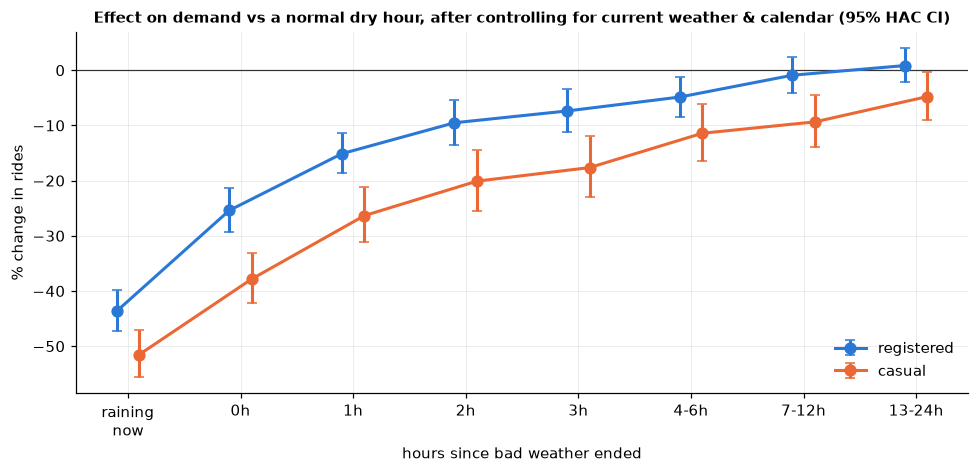

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(AFTER_ORDER) - 1)
for off, t in [(-0.1, 'registered'), (0.1, 'casual')]:
    c = coef[coef.rider == t].set_index('hours after').reindex(AFTER_ORDER[:-1])
    ax.errorbar(x + off, c['effect %'], yerr=[c['effect %'] - c['CI low %'], c['CI high %'] - c['effect %']],
                color=COL[t], marker='o', ms=7, capsize=3, lw=2, label=t)
ax.axhline(0, color='#333', lw=0.8)
ax.set_xticks(x, ['raining\nnow'] + AFTER_ORDER[1:-1])
ax.set(title='Effect on demand vs a normal dry hour, after controlling for current weather & calendar (95% HAC CI)',
       xlabel='hours since bad weather ended', ylabel='% change in rides')
ax.title.set_size(10)
ax.legend(frameon=False, loc='lower right')
savefig('fig09_regression_recovery_effect')

**Robustness check: is the "hangover" just lingering humidity?** Right after rain the air is still humid and misty (table below). Model B controls for humidity only *linearly*. Model C replaces it with **7 humidity bands, each with its own temperature slope** (muggy heat and cold damp air are allowed to differ). If the `after_bin` effects survive, the slow recovery is not just the humidity.

In [27]:
print('Weather in each recovery bin (mean):')
display(reg.groupby('after_bin', observed=True).agg(humidity=('hum_pct', 'mean'), mist_share=('ws2', 'mean'), temp_c=('temp_c', 'mean')).reindex(AFTER_ORDER).T.round(2))

reg['hum_band'] = pd.cut(reg.hum_pct, [0, 40, 50, 60, 70, 80, 90, 101]).astype(str)
FORM_C = f'{CAL} + ws2 + temp_c + I(temp_c**2) + wind_kmh + C(hum_band) + C(hum_band):temp_c + C(after_bin)'
robust = {}
for t in ['registered', 'casual']:
    r = smf.ols(f'np.log1p({t}) ~ {FORM_C}', data=reg).fit(cov_type='HAC', cov_kwds={'maxlags': 24})
    robust[f'{t}: model B'] = coef[coef.rider == t].set_index('hours after')['effect %']
    robust[f'{t}: model C (non-linear humidity)'] = pd.Series({b: np.expm1(r.params[f'C(after_bin)[T.{b}]']) * 100 for b in AFTER_ORDER[:-1]})
print('Effect (% change in rides vs a normal dry hour):')
pd.DataFrame(robust).reindex(AFTER_ORDER[:-1]).round(1)

Weather in each recovery bin (mean):


after_bin,bad now,0h,1h,2h,3h,4-6h,7-12h,13-24h,>24h
humidity,84.12,81.13,78.89,77.22,75.19,72.75,65.93,57.19,57.31
mist_share,0.00,0.79,0.69,0.62,0.46,0.40,0.28,0.20,0.24
temp_c,13.37,15.04,15.17,15.33,15.50,15.64,15.80,15.93,15.36


Effect (% change in rides vs a normal dry hour):


,registered: model B,registered: model C (non-linear humidity),casual: model B,casual: model C (non-linear humidity)
bad now,-43.7,-42.3,-51.5,-50.3
0h,-25.4,-24.3,-37.8,-36.0
1h,-15.1,-14.1,-26.3,-24.5
2h,-9.5,-8.9,-20.1,-18.6
3h,-7.4,-7.0,-17.6,-16.4
4-6h,-4.9,-4.5,-11.4,-10.3
7-12h,-0.9,-0.8,-9.4,-8.6
13-24h,0.8,1.1,-4.8,-3.8


**Reading: RQ-B answer (controlling for current weather).**

*Registered riders* are 25 % below normal in the first dry hour, then −15 % (1 h), **−9.5 % (2 h)**, −5 % (4–6 h), and **0 (not significant) from 7 h on**.

*Casual riders* are −38 % (0 h), −26 % (1 h), −20 % (2 h), −18 % (3 h), −11 % (4–6 h), and **still −9 % at 7–12 h and −5 % at 13–24 h** (HAC p < 0.05).

*Recovery time.* Using the same "within 10 % of normal" threshold, **registered riders recover in ~2 h and casual riders in ~7–12 h**. The regression gives shorter times than the episode view because it removes the effect of humidity and season. It is the more conservative estimate.

*Robustness.*
- **Model C** (non-linear humidity) changes the effects by at most 4 percentage points, so the hangover is not just the lingering humidity.
- **AIC** prefers Model B for both rider types (registered 16 067 → 15 773, casual 30 869 → 30 503).

**Model D: is the recovery different on days off?** The episode view hinted that registered riders recover slowly at weekends (n = 20). If true, the hangover would be about *trip purpose* rather than membership. We add one extra dummy per recovery bin that is 1 only on non-working days. Its coefficient is the *additional* % effect on days off. Explicit dummies are used because a patsy interaction with `workingday` would be collinear with the hour × day-type terms.

In [28]:
OFF = {b: f'off_{i}' for i, b in enumerate(AFTER_ORDER[:-1])}
for b, col in OFF.items():
    reg[col] = (reg.after_bin.astype(str).eq(b) & reg.workingday.eq(0)).astype(int)
FORM_D = f'{CAL} + {WEA} + C(after_bin) + ' + ' + '.join(OFF.values())
inter = {}
for t in ['registered', 'casual']:
    r = smf.ols(f'np.log1p({t}) ~ {FORM_D}', data=reg).fit(cov_type='HAC', cov_kwds={'maxlags': 24})
    inter[(t, 'extra % on days off')] = pd.Series({b: np.expm1(r.params[c]) * 100 for b, c in OFF.items()})
    inter[(t, 'p (HAC)')] = pd.Series({b: r.pvalues[c] for b, c in OFF.items()})
pd.DataFrame(inter).round(3)

registered                      casual        
        extra % on days off p (HAC) extra % on days off p (HAC)
bad now               9.194   0.287             -11.406   0.329
0h                    0.640   0.919              -6.762   0.406
1h                    1.961   0.690             -15.707   0.020
2h                   -2.174   0.678               0.421   0.956
3h                    2.856   0.549               2.644   0.709
4-6h                  1.692   0.708              -3.356   0.575
7-12h                 2.676   0.508              -0.670   0.906
13-24h                4.419   0.241               1.607   0.755

**Reading.** None of the registered day-off terms is significant (all p > 0.2). For casual riders only the 1 h bin is (−16 %, p = 0.02), which is what one test in 16 can produce by chance. **The recovery speed does not differ clearly between working days and days off.** The weekend hint from §6 was small-sample noise, so we do *not* claim a trip-purpose effect. The robust finding is the difference between the rider groups.

In [29]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

reg['h_after_c'] = reg.h_after.fillna(48).clip(upper=48).where(~reg.bad, -1)
reg['prev_dur_c'] = reg.prev_dur.where(reg.h_after_c.between(0, 47), 0).fillna(0)
F_A = ['hr', 'workingday', 'holiday', 'mnth', 'yr', 'weathersit', 'temp_c', 'hum_pct', 'wind_kmh']
F_B = F_A + ['h_after_c', 'prev_dur_c', 'bad_last6', 'bad_last24']
POST = ['0h', '1h', '2h', '3h', '4-6h']

def scores_(y, yhat):
    return {'MAE': mean_absolute_error(y, yhat), 'RMSE': np.sqrt(mean_squared_error(y, yhat)),
            'RMSLE': np.sqrt(mean_squared_error(np.log1p(y), np.log1p(yhat)))}

SPLIT = pd.Timestamp('2012-07-01')
train, test = reg[reg.index < SPLIT], reg[reg.index >= SPLIT]
post = test.after_bin.isin(POST).values
print(f'train {len(train)} h | test {len(test)} h, of which {post.sum()} post-rain hours (0–6 h after)')

res = []
for t in ['registered', 'casual']:
    preds = {}
    for m in FORM:
        preds[f'OLS {m}'] = np.expm1(smf.ols(f'np.log1p({t}) ~ {FORM[m]}', data=train).fit().predict(test)).clip(lower=0)
    for m, F in [('A', F_A), ('B', F_B)]:
        gb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=RANDOM_STATE)
        gb.fit(train[F], np.log1p(train[t]))
        preds[f'GBoost {m}'] = np.expm1(gb.predict(test[F])).clip(min=0)
    for name, p in preds.items():
        p = np.asarray(p)
        res.append({'target': t, 'model': name, 'subset': 'all test hours', **scores_(test[t].values, p)})
        res.append({'target': t, 'model': name, 'subset': 'post-rain 0–6 h', **scores_(test[t].values[post], p[post])})
res = pd.DataFrame(res)
res.pivot_table(index=['target', 'model'], columns='subset', values=['MAE', 'RMSE', 'RMSLE']).round(2)

train 13075 h | test 4380 h, of which 596 post-rain hours (0–6 h after)


MAE                           RMSE                          RMSLE                
subset              all test hours post-rain 0–6 h all test hours post-rain 0–6 h all test hours post-rain 0–6 h
target     model                                                                                                
casual     GBoost A          12.25           10.85          21.64           20.98           0.52            0.56
           GBoost B          12.17           10.59          21.62           19.62           0.51            0.58
           OLS A             15.09           10.82          27.71           18.03           0.57            0.61
           OLS B             14.74           11.02          27.22           19.30           0.56            0.58
registered GBoost A          42.28           35.61          66.60           59.85           0.39            0.42
           GBoost B          43.59           38.13          69.01           63.88           0.39            0.41
           OLS A             40.15           38.47          65.47           67.40           0.41            0.46
           OLS B             40.27           34.25          65.23           57.00           0.41            0.43

In [30]:
gain = res.pivot_table(index=['target', 'subset'], columns='model', values='MAE')
gain['OLS: B vs A MAE change %'] = (gain['OLS B'] / gain['OLS A'] - 1) * 100
gain['GBoost: B vs A MAE change %'] = (gain['GBoost B'] / gain['GBoost A'] - 1) * 100
display(gain.round(2))

# robustness: 5-fold expanding-window time-series CV (gradient boosting, post-rain MAE)
cv = []
for fold, (tr, te) in enumerate(TimeSeriesSplit(n_splits=5).split(reg)):
    a, b = reg.iloc[tr], reg.iloc[te]
    m_post = b.after_bin.isin(POST).values
    for t in ['registered', 'casual']:
        out = {}
        for m, F in [('A', F_A), ('B', F_B)]:
            gb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=RANDOM_STATE).fit(a[F], np.log1p(a[t]))
            p = np.expm1(gb.predict(b[F])).clip(min=0)
            out[m] = mean_absolute_error(b[t].values[m_post], p[m_post])
        cv.append({'fold': fold + 1, 'target': t, 'post-rain MAE A': out['A'], 'post-rain MAE B': out['B'],
                   'B vs A %': (out['B'] / out['A'] - 1) * 100})
cv = pd.DataFrame(cv)
print('TimeSeriesSplit (5 folds), post-rain MAE:')
display(cv.groupby('target')[['post-rain MAE A', 'post-rain MAE B', 'B vs A %']].agg(['mean', 'std']).round(2))

model                       GBoost A  GBoost B  OLS A  OLS B  OLS: B vs A MAE change %  GBoost: B vs A MAE change %
target     subset                                                                                                  
casual     all test hours      12.25     12.17  15.09  14.74                     -2.31                        -0.62
           post-rain 0–6 h     10.85     10.59  10.82  11.02                      1.87                        -2.39
registered all test hours      42.28     43.59  40.15  40.27                      0.30                         3.10
           post-rain 0–6 h     35.61     38.13  38.47  34.25                    -10.96                         7.08

TimeSeriesSplit (5 folds), post-rain MAE:


post-rain MAE A       post-rain MAE B        B vs A %       
                      mean   std            mean    std     mean    std
target                                                                 
casual               10.06  2.99           10.48   3.78     2.71   8.85
registered           36.26  7.15           43.74  11.46    20.12  15.88

In [31]:
# why does gradient boosting not gain from the lag features? -> look at model-A residuals per recovery bin on the test set
resid_tab = {}
for t in ['registered', 'casual']:
    gb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=RANDOM_STATE).fit(train[F_A], np.log1p(train[t]))
    ols_a = smf.ols(f'np.log1p({t}) ~ {FORM["A"]}', data=train).fit()
    r = pd.DataFrame({'bin': test.after_bin.astype(str).values,
                      'GBoost A': np.log1p(test[t]).values - gb.predict(test[F_A]),
                      'OLS A': np.log1p(test[t]).values - ols_a.predict(test).values})
    m = r.groupby('bin')[['GBoost A', 'OLS A']].mean().reindex(AFTER_ORDER)
    resid_tab[(t, 'GBoost A')], resid_tab[(t, 'OLS A')] = m['GBoost A'], m['OLS A']
print('Mean log residual (actual − predicted) of the CURRENT-WEATHER-ONLY models on the test set; negative = over-prediction:')
pd.DataFrame(resid_tab).T.round(3)

Mean log residual (actual − predicted) of the CURRENT-WEATHER-ONLY models on the test set; negative = over-prediction:


bin                  bad now     0h     1h     2h     3h   4-6h  7-12h  13-24h   >24h
registered GBoost A    0.202 -0.157 -0.038  0.036  0.040  0.008  0.019   0.046  0.072
           OLS A      -0.112 -0.367 -0.229 -0.139 -0.123 -0.145 -0.122  -0.116 -0.103
casual     GBoost A    0.215 -0.230 -0.031 -0.001 -0.079 -0.006  0.019   0.002  0.059
           OLS A       0.094 -0.317 -0.118 -0.092 -0.145 -0.104 -0.053   0.049  0.047

**Reading: prediction (the metric that matters for operations).**

*Linear model.* Adding the recovery clock cuts the **registered post-rain error by 11 % MAE (38.5 → 34.3 rides/h) and 15 % RMSE (67.4 → 57.0)** on the unseen Jul–Dec 2012 data. The error over all hours barely changes. That is exactly why the post-rain subset is the right evaluation set: an all-hours metric would hide the effect.

*Gradient boosting.* It does **not** gain from the lag features: registered post-rain MAE goes 35.6 → 38.1, and +20 % across the 5 time-series folds. The residual table explains why:
- The current-weather-only boosting model is already almost unbiased from 1 h after the rain on.
- The linear model over-predicts every post-rain bin.

The trees read "it has just rained" from the **current humidity and mist**, which stay high after rain (mist in 79 % of first dry hours vs 24 % normally; humidity 81 % vs 57 %). The extra lag columns then only add variance.

*Casual riders.* Counts are small, so MAE differences of ±0.3 rides/h are within noise and there is no consistent gain.

*Conclusion.* The hangover is real (§6, and Models B/C with HAC confidence intervals). For **forecasting**, the company needs a model that sees the post-rain state: either an explicit "hours since rain" feature in a simple model, or a flexible model with humidity and mist. "Hours since rain" is the one a dispatcher can read and the one a weather forecast gives directly.

## 8 · RQ-C: association rules. Which conditions *together* keep demand low after rain?

**Why.** Regression gives an *average* effect per hour bin. Association rules find **combinations** that the company can read directly, such as `{1 h after rain, weekend, cold} ⇒ casual = low`, without us guessing the interactions in advance.

| Decision | Choice | Reason |
|---|---|---|
| Transactions | one per **dry daytime hour** (07–21), no outage | we study the *after* period; night ratios are noise |
| Items | hours-since-rain bin, previous-episode length and type, daypart, day type, temperature band, high humidity, mist/clear, season | the representation built in §4 |
| Consequent | `casual` / `registered` = low (< 0.7 × normal), normal, high (> 1.3 × normal) | fixed, business-readable bands ("30 % below normal") instead of data-driven quantiles |
| Algorithm | Apriori, `min_support = 0.003` (≈ 30 hours), `max_len = 4` | post-rain hours are rare, so a high support would hide every rule we care about |
| Ranking | **lift**, then confidence; conviction also reported | confidence is inflated when the consequent is frequent ("registered = normal" is true most of the time); lift corrects for that |
| Validation | mine on **2011**, re-measure the same rules on **2012** | a rule the company can rely on must hold in a new year |

**Source.** Association rules, Apriori, support/confidence/lift [Lecture: Association Rules – Slide ?]; Agrawal & Srikant (1994).

In [32]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

ar = df[~df.outage & ~df.bad & df.hr.between(7, 21) & df.exp_cnt.notna()].copy()
LEVELS = [0, 0.7, 1.3, np.inf]
recent = ar.h_after <= 12
items = pd.DataFrame({
    'after': 'after=' + ar.after_bin.replace({'0h': '0-1h', '1h': '0-1h', '2h': '2-3h', '3h': '2-3h'}),
    'prev_len': np.where(recent, np.where(ar.prev_dur >= 4, 'prev=long(≥4h)', 'prev=short(2-3h)'), None),
    'prev_type': np.where(recent & ar.prev_type.eq('snow/ice'), 'prev=snow/ice', None),
    'daypart': 'time=' + ar.daypart,
    'day': np.where(ar.workingday == 1, 'day=working', 'day=off'),
    'temp': 'temp=' + pd.cut(ar.temp_c, [-np.inf, 10, 20, 28, np.inf], labels=['cold(<10)', 'mild(10-20)', 'warm(20-28)', 'hot(>28)']).astype(str),
    'hum': np.where(ar.hum_pct >= 80, 'hum=high(≥80%)', None),
    'sky': np.where(ar.weathersit == 2, 'sky=mist', 'sky=clear'),
    'season': 'season=' + ar.season_name,
    'casual': 'casual=' + pd.cut(ar.ratio_casual, LEVELS, labels=['low', 'normal', 'high']).astype(str),
    'registered': 'registered=' + pd.cut(ar.ratio_registered, LEVELS, labels=['low', 'normal', 'high']).astype(str),
}, index=ar.index)
# short episodes (1 h) count as 'short' too
items.loc[recent & (ar.prev_dur < 2), 'prev_len'] = 'prev=short(1h)'
transactions = [[v for v in row if isinstance(v, str)] for row in items.itertuples(index=False)]

te = TransactionEncoder()
X_ar = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_, index=ar.index)
print(f'{len(X_ar)} transactions, {X_ar.shape[1]} items')
print('consequent base rates:', X_ar[[c for c in X_ar if c.startswith(('casual=', 'registered='))]].mean().round(3).to_dict())

DEMAND = {c for c in X_ar.columns if c.startswith(('casual=', 'registered='))}

def mine(X, min_support=0.003):
    freq = apriori(X, min_support=min_support, use_colnames=True, max_len=4)
    rules = association_rules(freq, num_itemsets=len(X), metric='lift', min_threshold=1.0)
    keep = (rules.consequents.apply(lambda s: len(s) == 1 and next(iter(s)) in DEMAND)
            & rules.antecedents.apply(lambda s: not (s & DEMAND))
            & rules.antecedents.apply(lambda s: any(i.startswith('after=') and i != 'after=>24h' for i in s)))
    return rules[keep]

fmt = lambda s: ', '.join(sorted(s))
rules = mine(X_ar)
for target in ['registered=low', 'casual=low']:
    sub = rules[rules.consequents.apply(lambda s: next(iter(s)) == target) & (rules.confidence >= 0.4)]
    top = sub.sort_values(['lift', 'confidence'], ascending=False).head(8)
    print(f'Top rules  ⇒ {target}   (base rate {X_ar[target].mean():.1%}, {len(sub)} rules with confidence ≥ 0.4)')
    display(top.assign(antecedents=top.antecedents.apply(fmt))[['antecedents', 'support', 'confidence', 'lift', 'conviction']].round(3))

10000 transactions, 33 items
consequent base rates: {'casual=high': 0.186, 'casual=low': 0.245, 'casual=normal': 0.569, 'registered=high': 0.055, 'registered=low': 0.095, 'registered=normal': 0.85}


Top rules  ⇒ registered=low   (base rate 9.5%, 48 rules with confidence ≥ 0.4)


,antecedents,support,confidence,lift,conviction
13782,"after=0-1h, hum=high(≥80%), time=PM peak",0.005,0.654,6.883,2.614
14187,"after=0-1h, prev=long(≥4h), time=midday",0.003,0.640,6.737,2.514
13395,"after=0-1h, hum=high(≥80%), prev=long(≥4h)",0.007,0.629,6.617,2.437
13702,"after=0-1h, hum=high(≥80%), season=summer",0.004,0.625,6.579,2.413
14174,"after=0-1h, prev=long(≥4h), time=PM peak",0.003,0.612,6.445,2.334
14146,"after=0-1h, prev=long(≥4h), sky=mist",0.007,0.595,6.261,2.234
835,"after=0-1h, prev=long(≥4h)",0.008,0.592,6.227,2.216
12493,"after=0-1h, day=working, prev=long(≥4h)",0.006,0.582,6.124,2.164


Top rules  ⇒ casual=low   (base rate 24.5%, 232 rules with confidence ≥ 0.4)


,antecedents,support,confidence,lift,conviction
10902,"after=0-1h, prev=long(≥4h), time=midday",0.004,0.900,3.667,7.546
11438,"after=0-1h, season=spring, temp=cold(<10)",0.003,0.850,3.464,5.031
10544,"after=0-1h, hum=high(≥80%), prev=long(≥4h)",0.009,0.838,3.415,4.661
10848,"after=0-1h, prev=long(≥4h), temp=cold(<10)",0.005,0.831,3.384,4.452
22648,"after=4-6h, day=off, temp=cold(<10)",0.003,0.829,3.379,4.420
11694,"after=0-1h, temp=cold(<10), time=midday",0.004,0.822,3.351,4.245
10740,"after=0-1h, hum=high(≥80%), time=PM peak",0.006,0.821,3.344,4.204
10834,"after=0-1h, prev=long(≥4h), sky=mist",0.010,0.819,3.337,4.168


In [33]:
# which single 'after=' items predict low demand, and for whom? (the simplest, most readable rules)
simple = rules[rules.antecedents.apply(len) == 1].copy()
simple = simple.assign(antecedents=simple.antecedents.apply(fmt), consequents=simple.consequents.apply(fmt))
print('One-item rules  {hours since rain} ⇒ {demand level}:')
display(simple[simple.consequents.str.endswith('=low')].sort_values(['consequents', 'antecedents'])[
    ['antecedents', 'consequents', 'support', 'confidence', 'lift']].round(3))

# stability: mine on 2011, re-measure on 2012
is11 = X_ar.index.year == 2011
X11, X12 = X_ar[is11], X_ar[~is11]
r11 = mine(X11)
r11 = r11[r11.consequents.apply(lambda s: next(iter(s)).endswith('=low')) & (r11.confidence >= 0.4)].sort_values('lift', ascending=False).head(20)

def measure(X, ante, cons):
    a = X[list(ante)].all(axis=1)
    c = X[list(cons)].all(axis=1)
    conf = (a & c).sum() / a.sum() if a.sum() else np.nan
    return pd.Series({'support 2012': (a & c).mean(), 'confidence 2012': conf, 'lift 2012': conf / c.mean() if c.mean() else np.nan})

stab = pd.concat([r11.reset_index(drop=True)[['antecedents', 'consequents', 'confidence', 'lift']].rename(columns={'confidence': 'confidence 2011', 'lift': 'lift 2011'}),
                  pd.DataFrame([measure(X12, a, c) for a, c in zip(r11.antecedents, r11.consequents)])], axis=1)
stab['antecedents'] = stab.antecedents.apply(fmt); stab['consequents'] = stab.consequents.apply(fmt)
print(f'top-{len(stab)} 2011 rules: lift still > 1.2 in 2012 for {(stab["lift 2012"] > 1.2).mean():.0%}; '
      f'median lift 2011 {stab["lift 2011"].median():.2f} -> 2012 {stab["lift 2012"].median():.2f}')
stab.round(3)

One-item rules  {hours since rain} ⇒ {demand level}:


,antecedents,consequents,support,confidence,lift
0,after=0-1h,casual=low,0.034,0.625,2.546
30,after=13-24h,casual=low,0.039,0.257,1.049
52,after=2-3h,casual=low,0.021,0.487,1.985
76,after=4-6h,casual=low,0.019,0.387,1.578
108,after=7-12h,casual=low,0.025,0.293,1.193
12,after=0-1h,registered=low,0.022,0.401,4.218
64,after=2-3h,registered=low,0.008,0.181,1.907


top-20 2011 rules: lift still > 1.2 in 2012 for 100%; median lift 2011 6.57 -> 2012 5.65


,antecedents,consequents,confidence 2011,lift 2011,support 2012,confidence 2012,lift 2012
0,"after=0-1h, hum=high(≥80%), season=summer",registered=low,0.815,8.306,0.003,0.448,4.874
1,"after=0-1h, prev=long(≥4h), season=spring",registered=low,0.789,8.048,0.002,0.529,5.756
2,"after=0-1h, prev=long(≥4h), temp=mild(10-20)",registered=low,0.739,7.535,0.002,0.478,5.200
3,"after=0-1h, prev=long(≥4h), time=midday",registered=low,0.708,7.221,0.003,0.577,6.273
4,"after=0-1h, hum=high(≥80%), sky=clear",registered=low,0.679,6.917,0.001,0.278,3.020
5,"after=0-1h, hum=high(≥80%), prev=long(≥4h)",registered=low,0.667,6.796,0.006,0.583,6.343
6,"after=0-1h, temp=cold(<10), time=PM peak",registered=low,0.667,6.796,0.002,0.692,7.528
7,"after=0-1h, hum=high(≥80%), temp=warm(20-28)",registered=low,0.658,6.706,0.003,0.415,4.508
8,"after=0-1h, prev=long(≥4h), time=PM peak",registered=low,0.655,6.679,0.002,0.550,5.980
9,"after=0-1h, hum=high(≥80%), time=PM peak",registered=low,0.644,6.569,0.004,0.667,7.249


**Reading: RQ-C answer (rules).**

*One-item rules mirror the regression.*
- `{0–1 h after} ⇒ registered = low` has lift 4.2, then lift 1.9 at 2–3 h, and **no rule at all after 3 h** (lift ≤ 1 or support < 0.3 %).
- `⇒ casual = low` stays above lift 1 much longer: 2.5 (0–1 h), 2.0 (2–3 h), 1.6 (4–6 h), 1.2 (7–12 h), 1.05 (13–24 h).

Two independent methods give the same answer: commuters come back within ~3 h; casual riders take about half a day.

*Strongest combined rules.*
- `{0–1 h after, previous episode ≥ 4 h, midday} ⇒ casual = low`: confidence 0.90, lift 3.7.
- `{0–1 h after, high humidity, PM peak} ⇒ registered = low`: confidence 0.65, lift 6.9.
- `{4–6 h after, day off, cold} ⇒ casual = low`: confidence 0.83, lift 3.4. On a cold weekend the casual hangover lasts at least 6 h.

*Why lift and not confidence.* `casual = low` has a 24.5 % base rate, so a confidence of 0.40 sounds strong but is only lift 1.6. `registered = low` has a 9.5 % base rate, so confidence 0.40 is already lift 4.2. Ranking by confidence alone would systematically favour casual rules.

*Stability.* All 20 top rules mined on **2011** still have lift > 1.2 in **2012** (median lift 6.6 → 5.7). Confidence drops somewhat (the system grew, which changes the base rates), but the direction holds. These rules can be used operationally.

## 9 · Business translation: how many rides are lost *after* the weather has cleared?

**Why.** The criteria put particular weight on "the gain for the bike rental company". We turn the regression into rides with a **counterfactual**: we predict every post-rain hour twice with Model B, once as it happened and once as if it were a normal dry hour (`after_bin = >24h`), keeping the *current* weather fixed. The difference is the ride loss caused purely by the **recency** of bad weather. We do the same for the rain hours themselves, for comparison.

In [34]:
POST_ALL = ['0h', '1h', '2h', '3h', '4-6h', '7-12h', '13-24h']
loss = {}
for t in ['registered', 'casual']:
    m = ols[(t, 'B')]
    cf = reg.copy()
    cf['after_bin'] = pd.Categorical(np.where(reg.after_bin.isin(POST_ALL + ['bad now']), '>24h', reg.after_bin.astype(str)),
                                     categories=reg.after_bin.cat.categories)
    fitted, normal_ = np.expm1(m.predict(reg)), np.expm1(m.predict(cf))
    lost = (normal_ - fitted)
    loss[t] = {'during rain/snow': lost[reg.after_bin.eq('bad now')].sum() / 2,
               'after: 0–6 h': lost[reg.after_bin.isin(POST)].sum() / 2,
               'after: 7–24 h': lost[reg.after_bin.isin(['7-12h', '13-24h'])].sum() / 2}
loss = pd.DataFrame(loss)
loss['total'] = loss.sum(axis=1)
loss.loc['share lost after the weather cleared (0–24 h)'] = loss.loc[['after: 0–6 h', 'after: 7–24 h']].sum() / loss.iloc[:3].sum()
print('Rides per YEAR lost to bad weather (model-based counterfactual, current weather held fixed):')
loss.round(2)

Rides per YEAR lost to bad weather (model-based counterfactual, current weather held fixed):


,registered,casual,total
during rain/snow,47023.93,9787.62,56811.55
after: 0–6 h,21603.38,7351.52,28954.90
after: 7–24 h,-668.18,4421.74,3753.55
share lost after the weather cleared (0–24 h),0.31,0.55,0.37


### Findings and recommendations (draft for the report and slides)

**Answer to the research question.** Yes, demand stays low after bad weather ends, and the two rider groups recover at very different speeds:

| | Registered (commuters) | Casual (leisure) |
|---|---|---|
| first dry hour, vs normal | −25 % (regression) / 71 % of normal (episodes) | −38 % / 54 % of normal |
| back within 10 % of normal | **~2 h** (regression), median 3 h (episodes) | **~7–12 h** (regression), median 11 h (episodes) |
| still measurable after 12 h? | no | yes (−5 % at 13–24 h) |
| rides lost per year *after* the weather cleared | ≈ 20 900 (31 % of their weather loss) | ≈ 11 800 (**55 %** of their weather loss) |

Overall, **≈ 32 700 of ≈ 89 500 weather-related lost rides per year (37 %) are lost *after* the rain or snow has stopped.** A forecast that only looks at the current weather cannot see them.

**Recommendations for Capital Bikeshare.**
1. **Forecast with a recovery clock.** Add "hours since rain/snow ended" (or a flexible model with humidity and mist) to the demand forecast. Without it, registered post-rain demand is over-predicted, and the linear model's post-rain error is 11 % higher.
2. **Time the rebalancing to the commuters.** Commuter docks need their normal stock about **2 h after the rain stops**, not at the moment it stops. Leisure docks (Mall, waterfront) stay under-used for **~7–12 h**. That window is free truck time for moving bikes and for maintenance.
3. **Promote where the hangover is longest.** The rules point to *weekends, cold days, and the hours after long episodes* (`{0–1 h, long episode, midday} ⇒ casual low`, confidence 0.90). This is the slot for an app push ("the sun is out, 24-h pass discount"). It targets the ≈ 11 800 casual rides a year that are lost *after* the weather has already cleared.
4. **Fix the holiday calendar.** Christmas Eve 2012 and the days after Thanksgiving behave like holidays but are not flagged. A `bridge_day` feature would remove false anomalies from every model.

**Caveats.**
- The findings are in rides, not revenue; ride prices would come from the company.
- weathersit 3 mixes light rain and light snow, and the snow proxy has only 22 episodes.
- The data is from one city over two years.